In [27]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json
import random
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

EXPERIMENT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment"
)

BASELINE_CHECKPOINT = EXPERIMENT_DIR / "grape_best_model.pth"
LAST_ADAPTATION = EXPERIMENT_DIR / "grape_field_adapted_last.pth"
BEST_ADAPTATION = EXPERIMENT_DIR / "grape_field_adapted_best.pth"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

CLASS_NAMES = [
    "healthy",
    "downy_mildew",
    "powdery_mildew",
    "esca_complex",
    "erineum_mite",
]
CLASS_TO_INDEX = {name: i for i, name in enumerate(CLASS_NAMES)}

print("Device:", DEVICE)
print("Baseline checkpoint exists:", BASELINE_CHECKPOINT.exists())
print("Latest adaptation checkpoint exists:", LAST_ADAPTATION.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
Baseline checkpoint exists: True
Latest adaptation checkpoint exists: True


In [28]:
from PIL import Image, ImageOps, ImageFilter
from torch.utils.data import Dataset, DataLoader, ConcatDataset
from torchvision.transforms import functional as TF
from torchvision.transforms import ColorJitter

IMAGE_SIZE = 448
TILE_SIZE = 288
TILE_STARTS = [0, IMAGE_SIZE - TILE_SIZE]

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

color_jitter = ColorJitter(
    brightness=0.12,
    contrast=0.12,
    saturation=0.08,
    hue=0.02,
)

def prepare_image(image_path, training=False):
    image = Image.open(image_path)
    image = ImageOps.exif_transpose(image).convert("RGB")

    if training:
        if random.random() < 0.5:
            image = TF.hflip(image)

        angle = random.uniform(-12, 12)
        image = TF.rotate(image, angle, fill=(127, 127, 127))
        image = color_jitter(image)

        if random.random() < 0.08:
            image = image.filter(
                ImageFilter.GaussianBlur(
                    radius=random.uniform(0.1, 0.5)
                )
            )

    image = ImageOps.pad(
        image,
        (IMAGE_SIZE, IMAGE_SIZE),
        method=Image.Resampling.LANCZOS,
        color=(127, 127, 127),
    )

    return TF.to_tensor(image), image


class GrapeImageDataset(Dataset):
    def __init__(self, dataframe, training=False):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.training = training

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image_tensor, padded_image = prepare_image(
            row["image_path"],
            training=self.training,
        )

        tiles = []
        for top in TILE_STARTS:
            for left in TILE_STARTS:
                tile = padded_image.crop(
                    (left, top, left + TILE_SIZE, top + TILE_SIZE)
                )
                tiles.append(TF.to_tensor(tile))

        mean = torch.tensor(MEAN).view(3, 1, 1)
        std = torch.tensor(STD).view(3, 1, 1)

        image_tensor = (image_tensor - mean) / std
        tile_tensor = torch.stack([
            (tile - mean) / std for tile in tiles
        ])

        target = CLASS_TO_INDEX[row["label"]]
        return image_tensor, tile_tensor, target

In [29]:
from torchvision import models


class SpatialSelfAttention(nn.Module):
    def __init__(self, channels=256, heads=4, attention_size=14):
        super().__init__()
        self.attention_size = attention_size
        self.attention = nn.MultiheadAttention(
            embed_dim=channels,
            num_heads=heads,
            batch_first=True,
        )
        self.norm = nn.LayerNorm(channels)
        self.gate = nn.Conv2d(channels * 2, channels, kernel_size=1)

    def forward(self, feature_map):
        original_size = feature_map.shape[-2:]
        small = F.adaptive_avg_pool2d(
            feature_map,
            (self.attention_size, self.attention_size),
        )
        tokens = small.flatten(2).transpose(1, 2)

        attended, _ = self.attention(
            tokens, tokens, tokens, need_weights=False
        )
        tokens = self.norm(tokens + attended)

        context = tokens.transpose(1, 2).reshape(
            feature_map.shape[0],
            feature_map.shape[1],
            self.attention_size,
            self.attention_size,
        )
        context = F.interpolate(
            context,
            size=original_size,
            mode="bilinear",
            align_corners=False,
        )

        gate = torch.sigmoid(
            self.gate(torch.cat([feature_map, context], dim=1))
        )
        return feature_map + gate * context


class GrapeResNet50Attention(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        backbone = models.resnet50(weights=None)

        self.stem = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool,
        )
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        fusion_channels = 256
        self.project2 = nn.Conv2d(512, fusion_channels, kernel_size=1)
        self.project3 = nn.Conv2d(1024, fusion_channels, kernel_size=1)
        self.project4 = nn.Conv2d(2048, fusion_channels, kernel_size=1)

        self.fusion = nn.Sequential(
            nn.Conv2d(
                fusion_channels * 3,
                fusion_channels,
                kernel_size=3,
                padding=1,
            ),
            nn.BatchNorm2d(fusion_channels),
            nn.ReLU(inplace=True),
        )

        self.self_attention = SpatialSelfAttention(fusion_channels)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.tile_score = nn.Linear(fusion_channels, 1)

        self.classifier = nn.Sequential(
            nn.LayerNorm(fusion_channels * 3),
            nn.Dropout(0.35),
            nn.Linear(fusion_channels * 3, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.25),
            nn.Linear(512, num_classes),
        )

    def encode_view(self, images):
        x = self.stem(images)
        x = self.layer1(x)

        fine = self.layer2(x)
        middle = self.layer3(fine)
        deep = self.layer4(middle)

        output_size = fine.shape[-2:]
        fine = self.project2(fine)
        middle = F.interpolate(
            self.project3(middle),
            size=output_size,
            mode="bilinear",
            align_corners=False,
        )
        deep = F.interpolate(
            self.project4(deep),
            size=output_size,
            mode="bilinear",
            align_corners=False,
        )

        fused = self.fusion(torch.cat([fine, middle, deep], dim=1))
        attended = self.self_attention(fused)
        return self.pool(attended).flatten(1)

    def forward(self, full_images, tile_images):
        full_features = self.encode_view(full_images)

        batch_size, tile_count, channels, height, width = tile_images.shape
        flat_tiles = tile_images.reshape(
            batch_size * tile_count, channels, height, width
        )
        tile_features = self.encode_view(flat_tiles).reshape(
            batch_size, tile_count, -1
        )

        tile_weights = torch.softmax(
            self.tile_score(tile_features).squeeze(-1),
            dim=1,
        )
        weighted_tiles = (
            tile_features * tile_weights.unsqueeze(-1)
        ).sum(dim=1)
        strongest_tile = tile_features.max(dim=1).values

        combined = torch.cat(
            [full_features, weighted_tiles, strongest_tile],
            dim=1,
        )
        return self.classifier(combined)


baseline = torch.load(
    BASELINE_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False,
)

model = GrapeResNet50Attention(
    num_classes=len(CLASS_NAMES)
).to(DEVICE)

model.load_state_dict(baseline["model_state_dict"], strict=True)
model.eval()

print("Original baseline loaded.")
print("Checkpoint epoch:", baseline.get("epoch"))
print("All checkpoint parameters matched.")

Original baseline loaded.
Checkpoint epoch: 10
All checkpoint parameters matched.


In [30]:
internal_test_df = pd.read_csv(
    EXPERIMENT_DIR / "internal_test_manifest.csv"
)

missing = [
    path for path in internal_test_df["image_path"]
    if not Path(path).exists()
]
if missing:
    raise FileNotFoundError(
        f"{len(missing)} internal test images are missing. "
        f"First missing path: {missing[0]}"
    )

internal_test_dataset = GrapeImageDataset(
    internal_test_df,
    training=False,
)
internal_test_loader = DataLoader(
    internal_test_dataset,
    batch_size=3,
    shuffle=False,
    num_workers=0,
    pin_memory=USE_AMP,
)

print("Internal test images:", len(internal_test_dataset))

Internal test images: 789


In [31]:
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

model.eval()
y_true, y_pred = [], []

with torch.inference_mode():
    for full_images, tile_images, targets in tqdm(
        internal_test_loader,
        desc="Verifying original baseline",
    ):
        full_images = full_images.to(DEVICE, non_blocking=True)
        tile_images = tile_images.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP,
        ):
            logits = model(full_images, tile_images)

        y_true.extend(targets.tolist())
        y_pred.extend(logits.argmax(dim=1).cpu().tolist())

print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
print(
    "Macro-F1:",
    f"{f1_score(y_true, y_pred, average='macro', zero_division=0):.4f}",
)

Verifying original baseline:   0%|          | 0/263 [00:00<?, ?it/s]

Accuracy: 0.9658
Macro-F1: 0.9661


In [32]:
train_df = pd.read_csv(EXPERIMENT_DIR / "train_manifest.csv")
field_train_df = pd.read_csv(
    EXPERIMENT_DIR / "field_adaptation_train_manifest.csv"
)
field_val_df = pd.read_csv(
    EXPERIMENT_DIR / "field_adaptation_val_manifest.csv"
)

for name, dataframe in [
    ("Portuguese train", train_df),
    ("FieldVitis adaptation train", field_train_df),
    ("FieldVitis adaptation validation", field_val_df),
]:
    missing = [
        path for path in dataframe["image_path"]
        if not Path(path).exists()
    ]
    if missing:
        raise FileNotFoundError(
            f"{name}: {len(missing)} image paths are missing. "
            f"First missing path: {missing[0]}"
        )

portuguese_dataset = GrapeImageDataset(train_df, training=True)
field_train_dataset = GrapeImageDataset(field_train_df, training=True)
field_val_dataset = GrapeImageDataset(field_val_df, training=False)

adaptation_train_dataset = ConcatDataset(
    [portuguese_dataset, field_train_dataset]
)

adaptation_train_loader = DataLoader(
    adaptation_train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=0,
    pin_memory=USE_AMP,
)

field_adaptation_val_loader = DataLoader(
    field_val_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0,
    pin_memory=USE_AMP,
)

print("Portuguese train:", len(portuguese_dataset))
print("FieldVitis adaptation train:", len(field_train_dataset))
print("Combined train:", len(adaptation_train_dataset))
print("FieldVitis validation:", len(field_val_dataset))

Portuguese train: 3678
FieldVitis adaptation train: 268
Combined train: 3946
FieldVitis validation: 90


In [33]:
adapted_model = GrapeResNet50Attention(
    num_classes=len(CLASS_NAMES)
).to(DEVICE)

# Start from exact baseline weights, then restore adaptation checkpoint below.
adapted_model.load_state_dict(
    baseline["model_state_dict"],
    strict=True,
)

for parameter in adapted_model.parameters():
    parameter.requires_grad = False
for parameter in adapted_model.classifier.parameters():
    parameter.requires_grad = True

adaptation_optimizer = torch.optim.AdamW(
    adapted_model.classifier.parameters(),
    lr=1e-5,
    weight_decay=1e-3,
)
adaptation_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    adaptation_optimizer,
    mode="max",
    factor=0.5,
    patience=1,
)
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

checkpoint = torch.load(
    LAST_ADAPTATION,
    map_location=DEVICE,
    weights_only=False,
)

adapted_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True,
)
adaptation_optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)
adaptation_scheduler.load_state_dict(
    checkpoint["scheduler_state_dict"]
)

start_epoch = checkpoint["epoch"] + 1
adaptation_best_f1 = checkpoint["best_field_val_f1"]
adaptation_bad_epochs = checkpoint["bad_epochs"]
adaptation_history = checkpoint.get("history", [])

print("Resuming at adaptation epoch:", start_epoch)
print("Best FieldVitis validation macro-F1 so far:", adaptation_best_f1)

/tmp/ipykernel_602/1323033888.py:27: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


Resuming at adaptation epoch: 2
Best FieldVitis validation macro-F1 so far: 0.24888888888888888


In [34]:
from tqdm.auto import tqdm
from sklearn.metrics import f1_score, balanced_accuracy_score
import numpy as np
import pandas as pd
import torch

ADAPTATION_EPOCHS = 8
ADAPTATION_PATIENCE = 3

# Recreate the original Portuguese class weights used by the training loss.
class_counts = np.array([
    (train_df["label"] == class_name).sum()
    for class_name in CLASS_NAMES
], dtype=np.float32)

class_weights = len(train_df) / (len(CLASS_NAMES) * class_counts)
class_weights = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)
class_weights = class_weights / class_weights.mean()


class FocalLoss(nn.Module):
    def __init__(self, class_weights=None, gamma=1.5):
        super().__init__()
        self.gamma = gamma
        self.register_buffer("class_weights", class_weights)

    def forward(self, logits, targets):
        log_probs = F.log_softmax(logits, dim=1)
        log_pt = log_probs.gather(1, targets.unsqueeze(1)).squeeze(1)
        pt = log_pt.exp()
        weights = self.class_weights[targets]
        return (-weights * (1.0 - pt).pow(self.gamma) * log_pt).mean()


criterion = FocalLoss(class_weights=class_weights, gamma=1.5)

# Only Healthy (0) and Esca (3) occur in this FieldVitis validation split.
FIELD_VALIDATION_LABELS = [
    CLASS_TO_INDEX["healthy"],
    CLASS_TO_INDEX["esca_complex"],
]


def evaluate_field_validation():
    adapted_model.eval()
    all_targets = []
    all_predictions = []
    total_loss = 0.0

    with torch.inference_mode():
        for full_images, tile_images, targets in field_adaptation_val_loader:
            full_images = full_images.to(DEVICE, non_blocking=True)
            tile_images = tile_images.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP,
            ):
                logits = adapted_model(full_images, tile_images)
                loss = criterion(logits, targets)

            total_loss += loss.item() * targets.size(0)
            all_targets.extend(targets.cpu().tolist())
            all_predictions.extend(logits.argmax(dim=1).cpu().tolist())

    field_f1 = f1_score(
        all_targets,
        all_predictions,
        labels=FIELD_VALIDATION_LABELS,
        average="macro",
        zero_division=0,
    )
    field_balanced_accuracy = balanced_accuracy_score(
        all_targets,
        all_predictions,
    )
    return total_loss / len(field_adaptation_val_loader.dataset), field_f1, field_balanced_accuracy


# Re-score the saved Epoch 1 checkpoint using only the two represented classes.
epoch1_val_loss, adaptation_best_f1, epoch1_balanced_accuracy = (
    evaluate_field_validation()
)

adaptation_bad_epochs = 0
adaptation_history = []

print(
    f"Saved Epoch 1 — field val loss: {epoch1_val_loss:.4f}, "
    f"Healthy/Esca macro-F1: {adaptation_best_f1:.4f}, "
    f"balanced accuracy: {epoch1_balanced_accuracy:.4f}"
)
print(f"Continuing from epoch {start_epoch}.")

# Rewrite the best checkpoint metadata with the corrected two-class metric.
torch.save(
    {
        "epoch": checkpoint["epoch"],
        "model_state_dict": adapted_model.state_dict(),
        "class_names": CLASS_NAMES,
        "field_validation_classes": ["healthy", "esca_complex"],
        "field_val_macro_f1": adaptation_best_f1,
        "field_val_balanced_accuracy": epoch1_balanced_accuracy,
    },
    BEST_ADAPTATION,
)


for epoch in range(start_epoch, ADAPTATION_EPOCHS + 1):
    # Keep frozen backbone BatchNorm layers in eval mode.
    adapted_model.eval()
    adapted_model.classifier.train()

    total_train_loss = 0.0
    train_targets = []
    train_predictions = []

    progress = tqdm(
        adaptation_train_loader,
        desc=f"Field adaptation epoch {epoch}/{ADAPTATION_EPOCHS}",
    )

    for full_images, tile_images, targets in progress:
        full_images = full_images.to(DEVICE, non_blocking=True)
        tile_images = tile_images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        adaptation_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP,
        ):
            logits = adapted_model(full_images, tile_images)
            loss = criterion(logits, targets)

        scaler.scale(loss).backward()
        scaler.unscale_(adaptation_optimizer)
        torch.nn.utils.clip_grad_norm_(
            adapted_model.classifier.parameters(),
            max_norm=1.0,
        )
        scaler.step(adaptation_optimizer)
        scaler.update()

        total_train_loss += loss.item() * targets.size(0)
        train_targets.extend(targets.detach().cpu().tolist())
        train_predictions.extend(logits.argmax(dim=1).detach().cpu().tolist())
        progress.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = total_train_loss / len(adaptation_train_loader.dataset)
    train_f1 = f1_score(
        train_targets,
        train_predictions,
        labels=list(range(len(CLASS_NAMES))),
        average="macro",
        zero_division=0,
    )

    val_loss, val_f1, val_balanced_accuracy = evaluate_field_validation()
    adaptation_scheduler.step(val_f1)

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_macro_f1": train_f1,
        "field_val_loss": val_loss,
        "field_val_macro_f1_healthy_esca": val_f1,
        "field_val_balanced_accuracy": val_balanced_accuracy,
    }
    adaptation_history.append(record)

    pd.DataFrame(adaptation_history).to_csv(
        EXPERIMENT_DIR / "grape_field_adaptation_history.csv",
        index=False,
    )

    print(
        f"\nEpoch {epoch} | "
        f"Train loss: {train_loss:.4f}, train macro-F1: {train_f1:.4f} | "
        f"Field validation loss: {val_loss:.4f}, "
        f"Healthy/Esca macro-F1: {val_f1:.4f}, "
        f"balanced accuracy: {val_balanced_accuracy:.4f}"
    )

    if val_f1 > adaptation_best_f1:
        adaptation_best_f1 = val_f1
        adaptation_bad_epochs = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": adapted_model.state_dict(),
                "class_names": CLASS_NAMES,
                "field_validation_classes": ["healthy", "esca_complex"],
                "field_val_macro_f1": val_f1,
                "field_val_balanced_accuracy": val_balanced_accuracy,
            },
            BEST_ADAPTATION,
        )
        print("Saved new best field-adapted checkpoint.")
    else:
        adaptation_bad_epochs += 1

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": adapted_model.state_dict(),
            "optimizer_state_dict": adaptation_optimizer.state_dict(),
            "scheduler_state_dict": adaptation_scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "best_field_val_f1": adaptation_best_f1,
            "bad_epochs": adaptation_bad_epochs,
            "history": adaptation_history,
            "class_names": CLASS_NAMES,
        },
        LAST_ADAPTATION,
    )
    print("Saved latest completed adaptation checkpoint.")

    if adaptation_bad_epochs >= ADAPTATION_PATIENCE:
        print("Early stopping: field validation score did not improve.")
        break

print(f"\nBest Healthy/Esca field validation macro-F1: {adaptation_best_f1:.4f}")
print("Best adapted model:", BEST_ADAPTATION)
print("Latest resumable checkpoint:", LAST_ADAPTATION)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Saved Epoch 1 — field val loss: 0.8016, Healthy/Esca macro-F1: 0.6222, balanced accuracy: 0.6300
Continuing from epoch 2.


Field adaptation epoch 2/8:   0%|          | 0/1973 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")



Epoch 2 | Train loss: 0.0483, train macro-F1: 0.9717 | Field validation loss: 0.3932, Healthy/Esca macro-F1: 0.8188, balanced accuracy: 0.8100
Saved new best field-adapted checkpoint.
Saved latest completed adaptation checkpoint.


...


Epoch 6 | Train loss: 0.0264, train macro-F1: 0.9857 | Field validation loss: 0.2084, Healthy/Esca macro-F1: 0.8634, balanced accuracy: 0.8600
Saved new best field-adapted checkpoint.
Saved latest completed adaptation checkpoint.


Field adaptation epoch 7/8:   0%|          | 0/1973 [00:00<?, ?it/s]


Epoch 7 | Train loss: 0.0225, train macro-F1: 0.9837 | Field validation loss: 0.1896, Healthy/Esca macro-F1: 0.8743, balanced accuracy: 0.8700
Saved new best field-adapted checkpoint.
Saved latest completed adaptation checkpoint.


Field adaptation epoch 8/8:   0%|          | 0/1973 [00:00<?, ?it/s]


Epoch 8 | Train loss: 0.0191, train macro-F1: 0.9866 | Field validation loss: 0.1615, Healthy/Esca macro-F1: 0.9100, balanced accuracy: 0.9100
Saved new best field-adapted checkpoint.
Saved latest completed adaptation checkpoint.

Best Healthy/Esca field validation macro-F1: 0.9100
Best adapted model: /content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment/grape_field_adapted_best.pth
Latest resumable checkpoint: /content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment/grape_field_adapted_last.pth



Loaded Baseline checkpoint, epoch 10


Baseline: FieldVitis validation:   0%|          | 0/45 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")



Baseline — FieldVitis validation (Healthy/Esca)
Images: 90
Accuracy: 0.4778
Balanced accuracy: 0.4550
Macro-F1: 0.5474

Per-class results:
              precision    recall  f1-score   support

     healthy     0.7692    0.2500    0.3774        40
esca_complex     0.7857    0.6600    0.7174        50

   micro avg     0.7818    0.4778    0.5931        90
   macro avg     0.7775    0.4550    0.5474        90
weighted avg     0.7784    0.4778    0.5663        90



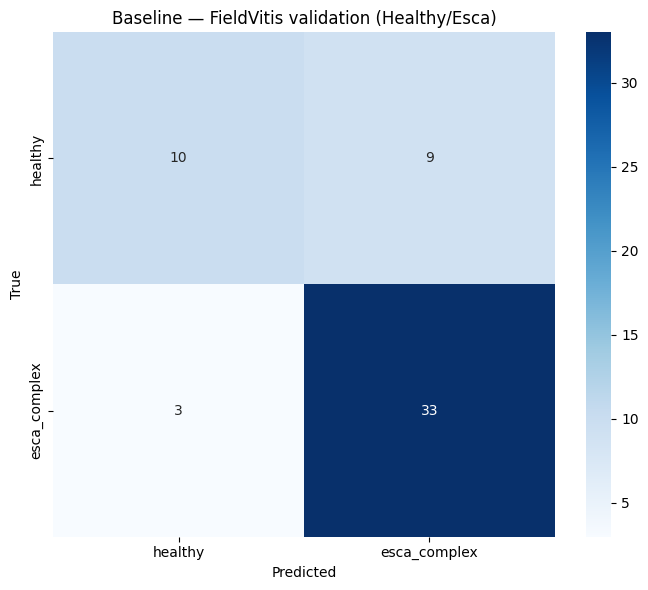

Baseline: Portuguese internal test:   0%|          | 0/263 [00:00<?, ?it/s]


Baseline — Portuguese internal test
Images: 789
Accuracy: 0.9658
Balanced accuracy: 0.9661
Macro-F1: 0.9661

Per-class results:
                precision    recall  f1-score   support

       healthy     0.9636    0.9464    0.9550       168
  downy_mildew     0.9592    0.9400    0.9495       150
powdery_mildew     0.9535    0.9704    0.9619       169
  esca_complex     0.9933    0.9933    0.9933       150
  erineum_mite     0.9613    0.9803    0.9707       152

      accuracy                         0.9658       789
     macro avg     0.9662    0.9661    0.9661       789
  weighted avg     0.9658    0.9658    0.9657       789



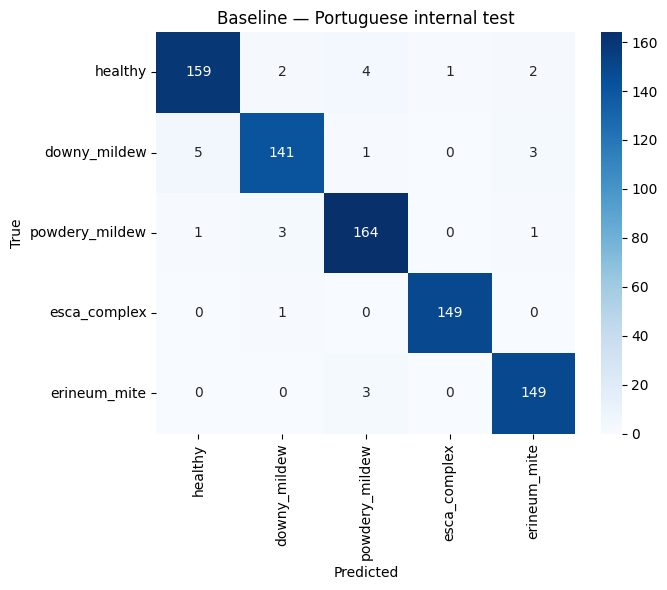


Loaded Field adapted checkpoint, epoch 8


Field adapted: FieldVitis validation:   0%|          | 0/45 [00:00<?, ?it/s]


Field adapted — FieldVitis validation (Healthy/Esca)
Images: 90
Accuracy: 0.9111
Balanced accuracy: 0.9100
Macro-F1: 0.9100

Per-class results:
              precision    recall  f1-score   support

     healthy     0.9000    0.9000    0.9000        40
esca_complex     0.9200    0.9200    0.9200        50

    accuracy                         0.9111        90
   macro avg     0.9100    0.9100    0.9100        90
weighted avg     0.9111    0.9111    0.9111        90



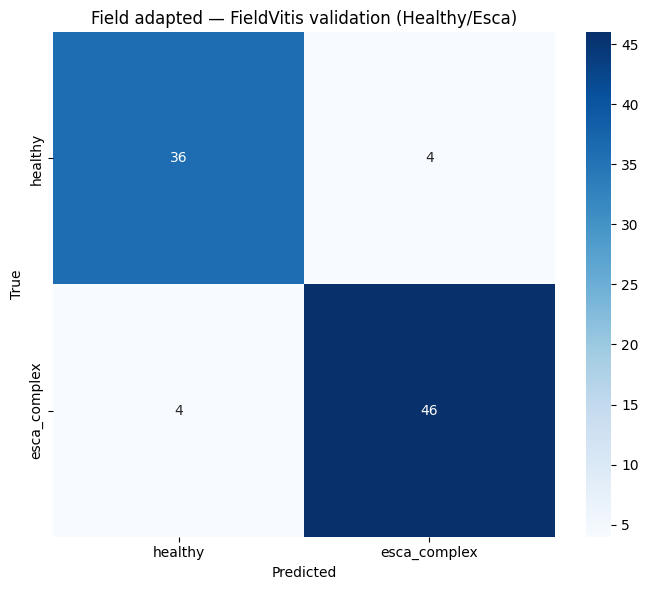

Field adapted: Portuguese internal test:   0%|          | 0/263 [00:00<?, ?it/s]


Field adapted — Portuguese internal test
Images: 789
Accuracy: 0.9670
Balanced accuracy: 0.9676
Macro-F1: 0.9673

Per-class results:
                precision    recall  f1-score   support

       healthy     0.9697    0.9524    0.9610       168
  downy_mildew     0.9467    0.9467    0.9467       150
powdery_mildew     0.9643    0.9586    0.9614       169
  esca_complex     0.9933    0.9933    0.9933       150
  erineum_mite     0.9615    0.9868    0.9740       152

      accuracy                         0.9670       789
     macro avg     0.9671    0.9676    0.9673       789
  weighted avg     0.9671    0.9670    0.9670       789



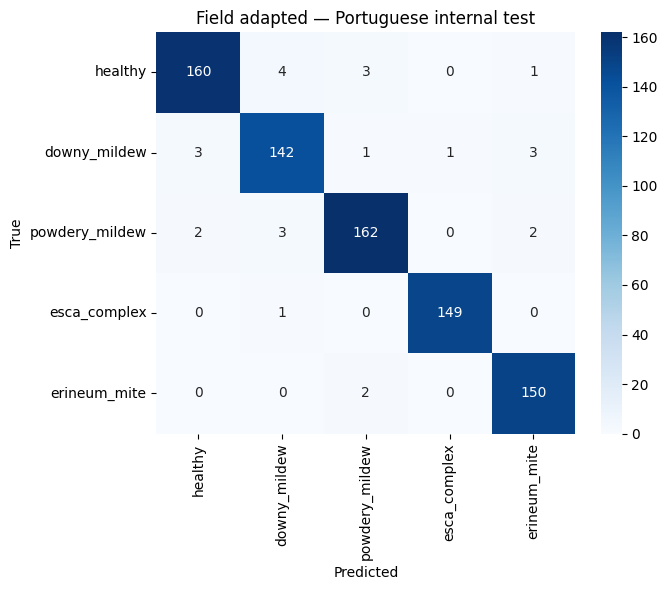


Saved comparison summary to:
/content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment/adaptation_evaluation/baseline_vs_adapted_summary.csv


,model,split,images,accuracy,balanced_accuracy,macro_f1
0,Baseline,FieldVitis validation (Healthy/Esca),90,0.477778,0.455000,0.547375
1,Baseline,Portuguese internal test,789,0.965779,0.966088,0.966069
2,Field adapted,FieldVitis validation (Healthy/Esca),90,0.911111,0.910000,0.910000
3,Field adapted,Portuguese internal test,789,0.967047,0.967561,0.967282


In [35]:
from pathlib import Path
import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

BASELINE_CHECKPOINT = EXPERIMENT_DIR / "grape_best_model.pth"
ADAPTED_CHECKPOINT = EXPERIMENT_DIR / "grape_field_adapted_best.pth"
RESULTS_DIR = EXPERIMENT_DIR / "adaptation_evaluation"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

if not BASELINE_CHECKPOINT.exists():
    raise FileNotFoundError(BASELINE_CHECKPOINT)
if not ADAPTED_CHECKPOINT.exists():
    raise FileNotFoundError(ADAPTED_CHECKPOINT)

# Use the exact preprocessing and dataset class from grapes1.ipynb.
internal_test_df = pd.read_csv(EXPERIMENT_DIR / "internal_test_manifest.csv")
field_val_df = pd.read_csv(
    EXPERIMENT_DIR / "field_adaptation_val_manifest.csv"
)

for dataframe in (internal_test_df, field_val_df):
    missing = [
        path for path in dataframe["image_path"]
        if not Path(path).exists()
    ]
    if missing:
        raise FileNotFoundError(
            f"{len(missing)} images are missing. First missing path: {missing[0]}"
        )

internal_test_dataset = GrapeImageDataset(
    internal_test_df,
    training=False,
)
field_val_dataset = GrapeImageDataset(
    field_val_df,
    training=False,
)

internal_test_loader = DataLoader(
    internal_test_dataset,
    batch_size=3,
    shuffle=False,
    num_workers=0,
    pin_memory=USE_AMP,
)
field_val_loader = DataLoader(
    field_val_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0,
    pin_memory=USE_AMP,
)

FIELD_CLASS_IDS = [
    CLASS_TO_INDEX["healthy"],
    CLASS_TO_INDEX["esca_complex"],
]


def predict_loader(model_to_test, loader, description):
    model_to_test.eval()
    targets_all, predictions_all = [], []

    with torch.inference_mode():
        for full_images, tile_images, targets in tqdm(
            loader, desc=description
        ):
            full_images = full_images.to(DEVICE, non_blocking=True)
            tile_images = tile_images.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP,
            ):
                logits = model_to_test(full_images, tile_images)

            targets_all.extend(targets.tolist())
            predictions_all.extend(logits.argmax(dim=1).cpu().tolist())

    return targets_all, predictions_all


def report_results(model_name, split_name, y_true, y_pred, labels):
    result = {
        "model": model_name,
        "split": split_name,
        "images": len(y_true),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=labels,
            average="macro",
            zero_division=0,
        ),
    }

    print(f"\n{'=' * 72}")
    print(f"{model_name} — {split_name}")
    print(f"{'=' * 72}")
    print("Images:", result["images"])
    print(f"Accuracy: {result['accuracy']:.4f}")
    print(f"Balanced accuracy: {result['balanced_accuracy']:.4f}")
    print(f"Macro-F1: {result['macro_f1']:.4f}")
    print("\nPer-class results:")
    print(classification_report(
        y_true,
        y_pred,
        labels=labels,
        target_names=[CLASS_NAMES[i] for i in labels],
        zero_division=0,
        digits=4,
    ))

    matrix = confusion_matrix(y_true, y_pred, labels=labels)
    matrix_df = pd.DataFrame(
        matrix,
        index=[CLASS_NAMES[i] for i in labels],
        columns=[CLASS_NAMES[i] for i in labels],
    )

    plt.figure(figsize=(7, 6))
    sns.heatmap(matrix_df, annot=True, fmt="d", cmap="Blues")
    plt.title(f"{model_name} — {split_name}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.tight_layout()

    safe_name = (
        f"{model_name}_{split_name}"
        .lower()
        .replace(" ", "_")
        .replace("/", "_")
    )
    plt.savefig(RESULTS_DIR / f"{safe_name}_confusion.png", dpi=160)
    plt.show()

    return result


summary_rows = []

for model_name, checkpoint_path in [
    ("Baseline", BASELINE_CHECKPOINT),
    ("Field adapted", ADAPTED_CHECKPOINT),
]:
    saved = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False,
    )

    model_to_test = GrapeResNet50Attention(
        num_classes=len(CLASS_NAMES)
    ).to(DEVICE)
    model_to_test.load_state_dict(
        saved["model_state_dict"],
        strict=True,
    )

    print(
        f"\nLoaded {model_name} checkpoint, "
        f"epoch {saved.get('epoch')}"
    )

    field_true, field_pred = predict_loader(
        model_to_test,
        field_val_loader,
        f"{model_name}: FieldVitis validation",
    )
    summary_rows.append(
        report_results(
            model_name,
            "FieldVitis validation (Healthy/Esca)",
            field_true,
            field_pred,
            FIELD_CLASS_IDS,
        )
    )

    internal_true, internal_pred = predict_loader(
        model_to_test,
        internal_test_loader,
        f"{model_name}: Portuguese internal test",
    )
    summary_rows.append(
        report_results(
            model_name,
            "Portuguese internal test",
            internal_true,
            internal_pred,
            list(range(len(CLASS_NAMES))),
        )
    )

    del model_to_test
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

summary_df = pd.DataFrame(summary_rows)
summary_path = RESULTS_DIR / "baseline_vs_adapted_summary.csv"
summary_df.to_csv(summary_path, index=False)

print("\nSaved comparison summary to:")
print(summary_path)
display(summary_df)

In [36]:
from pathlib import Path

OOD_ROOT = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_ood_data"
)

categories = [
    "unsupported_grape/grape_rot",
    "unsupported_grape/other_grape_condition",
    "other_crop_leaf",
    "non_plant",
]

for split in ["calibration", "test"]:
    for category in categories:
        (OOD_ROOT / split / category).mkdir(
            parents=True,
            exist_ok=True,
        )

print("OOD folders created under:", OOD_ROOT)
for split in ["calibration", "test"]:
    for category in categories:
        print(f"{split}/{category}: {OOD_ROOT / split / category}")

OOD folders created under: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data
calibration/unsupported_grape/grape_rot: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data/calibration/unsupported_grape/grape_rot
calibration/unsupported_grape/other_grape_condition: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data/calibration/unsupported_grape/other_grape_condition
calibration/other_crop_leaf: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data/calibration/other_crop_leaf
calibration/non_plant: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data/calibration/non_plant
test/unsupported_grape/grape_rot: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data/test/unsupported_grape/grape_rot
test/unsupported_grape/other_grape_condition: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data/test/unsupported_grape/other_grape_condition
test/other_crop_leaf: /content/drive/MyDrive/final_year_project/Grapes/grape_oo

In [37]:
from pathlib import Path

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for split in ["calibration", "test"]:
    print(f"\n{split.upper()}")
    print("-" * 60)

    for category in categories:
        folder = OOD_ROOT / split / category
        images = [
            path for path in folder.rglob("*")
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
        ]

        print(f"{category}: {len(images)} images")
        if images:
            print("  Example:", images[0].name)


CALIBRATION
------------------------------------------------------------
unsupported_grape/grape_rot: 0 images
unsupported_grape/other_grape_condition: 0 images
other_crop_leaf: 0 images
non_plant: 0 images

TEST
------------------------------------------------------------
unsupported_grape/grape_rot: 0 images
unsupported_grape/other_grape_condition: 0 images
other_crop_leaf: 0 images
non_plant: 0 images


In [38]:
from pathlib import Path
import hashlib
import pandas as pd
from sklearn.model_selection import train_test_split

DRIVE_GRAPES = Path(
    "/content/drive/MyDrive/final_year_project/Grapes"
)
FIELDVITIS_ROOT = DRIVE_GRAPES / "fieldvitis"
OOD_ROOT = DRIVE_GRAPES / "grape_ood_data"

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

if not FIELDVITIS_ROOT.exists():
    raise FileNotFoundError(f"FieldVitis folder not found: {FIELDVITIS_ROOT}")

# Find the two excluded FieldVitis disease folders.
wanted_classes = {
    "black_rot": "black_rot",
    "leaf_blight": "leaf_blight",
}
class_folders = {}

for folder in FIELDVITIS_ROOT.rglob("*"):
    if folder.is_dir() and folder.name.lower() in wanted_classes:
        class_folders[wanted_classes[folder.name.lower()]] = folder

missing_classes = set(wanted_classes.values()) - set(class_folders)
if missing_classes:
    raise FileNotFoundError(
        f"Could not find these FieldVitis folders: {sorted(missing_classes)}"
    )

ood_rows = []
for ood_label, folder in class_folders.items():
    for image_path in folder.rglob("*"):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            ood_rows.append({
                "image_path": str(image_path),
                "ood_category": ood_label,
                "source": "fieldvitis",
            })

ood_df = pd.DataFrame(ood_rows)
if ood_df.empty:
    raise ValueError("No images found in the Black Rot or Leaf Blight folders.")


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as image_file:
        for chunk in iter(lambda: image_file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


# Exclude any exact copies already used to train the supported grape model.
supported_train_paths = set()

for manifest_name in [
    "train_manifest.csv",
    "field_adaptation_train_manifest.csv",
]:
    manifest_path = EXPERIMENT_DIR / manifest_name
    manifest_df = pd.read_csv(manifest_path)
    supported_train_paths.update(manifest_df["image_path"].astype(str))

supported_hashes = {
    file_sha256(path)
    for path in supported_train_paths
    if Path(path).exists()
}

ood_df["sha256"] = ood_df["image_path"].map(file_sha256)
duplicate_mask = ood_df["sha256"].isin(supported_hashes)

print("Exact duplicates of supported training images removed:",
      int(duplicate_mask.sum()))
ood_df = ood_df.loc[~duplicate_mask].copy()

print("\nOOD images available after duplicate check:")
print(ood_df.groupby("ood_category").size())

# Make a stratified split so both unsupported conditions appear in each set.
ood_calibration_df, ood_test_df = train_test_split(
    ood_df,
    test_size=0.25,
    random_state=42,
    stratify=ood_df["ood_category"],
)

OOD_ROOT.mkdir(parents=True, exist_ok=True)
calibration_path = OOD_ROOT / "unsupported_grape_calibration_manifest.csv"
test_path = OOD_ROOT / "unsupported_grape_test_manifest.csv"

ood_calibration_df.drop(columns="sha256").to_csv(
    calibration_path, index=False
)
ood_test_df.drop(columns="sha256").to_csv(
    test_path, index=False
)

print("\nCalibration images:")
print(ood_calibration_df.groupby("ood_category").size())
print("\nOOD test images:")
print(ood_test_df.groupby("ood_category").size())
print("\nSaved manifests:")
print(calibration_path)
print(test_path)

Exact duplicates of supported training images removed: 0

OOD images available after duplicate check:
ood_category
black_rot       39
leaf_blight    158
dtype: int64

Calibration images:
ood_category
black_rot       29
leaf_blight    118
dtype: int64

OOD test images:
ood_category
black_rot      10
leaf_blight    40
dtype: int64

Saved manifests:
/content/drive/MyDrive/final_year_project/Grapes/grape_ood_data/unsupported_grape_calibration_manifest.csv
/content/drive/MyDrive/final_year_project/Grapes/grape_ood_data/unsupported_grape_test_manifest.csv


In [39]:
from pathlib import Path
import urllib.request
import zipfile

PROJECT_DIR = Path("/content/drive/MyDrive/final_year_project/Grapes")
OOD_DIR = PROJECT_DIR / "grape_ood_data"
PLANTDOC_DIR = OOD_DIR / "PlantDoc-Dataset"
ZIP_PATH = OOD_DIR / "plantdoc_master.zip"

OOD_DIR.mkdir(parents=True, exist_ok=True)

dataset_url = (
    "https://github.com/pratikkayal/PlantDoc-Dataset/"
    "archive/refs/heads/master.zip"
)

if not PLANTDOC_DIR.exists():
    print("Downloading PlantDoc...")
    urllib.request.urlretrieve(dataset_url, ZIP_PATH)

    print("Extracting PlantDoc...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(OOD_DIR)

    extracted_folder = OOD_DIR / "PlantDoc-Dataset-master"
    if extracted_folder.exists():
        extracted_folder.rename(PLANTDOC_DIR)

    ZIP_PATH.unlink(missing_ok=True)
else:
    print("PlantDoc already exists; skipping download.")

print("PlantDoc location:", PLANTDOC_DIR)
print("Top-level folders:")
for path in sorted(PLANTDOC_DIR.iterdir()):
    print(" ", path.name)

Extracting PlantDoc...
PlantDoc location: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data/PlantDoc-Dataset
Top-level folders:
  LICENSE.txt
  PlantDoc_Examples.png
  README.md
  test
  train


In [43]:
from pathlib import Path
from collections import Counter

PLANTDOC_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/"
    "grape_ood_data/PlantDoc-Dataset"
)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

if not PLANTDOC_DIR.exists():
    raise FileNotFoundError(f"PlantDoc folder not found: {PLANTDOC_DIR}")

class_counts = Counter()

for split_dir in ["train", "test"]:
    split_path = PLANTDOC_DIR / split_dir
    if not split_path.exists():
        print(f"Missing split folder: {split_path}")
        continue

    for image_path in split_path.rglob("*"):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            class_name = image_path.parent.name
            class_counts[class_name] += 1

print("PlantDoc image count:", sum(class_counts.values()))
print("\nImages by class:")
for class_name, count in sorted(class_counts.items()):
    print(f"{class_name}: {count}")

PlantDoc image count: 2578

Images by class:
Apple Scab Leaf: 93
Apple leaf: 91
Apple rust leaf: 89
Bell_pepper leaf: 61
Bell_pepper leaf spot: 71
Blueberry leaf: 117
Cherry leaf: 57
Corn Gray leaf spot: 68
Corn leaf blight: 192
Corn rust leaf: 116
Peach leaf: 112
Potato leaf early blight: 117
Potato leaf late blight: 105
Raspberry leaf: 119
Soyabean leaf: 65
Squash Powdery mildew leaf: 130
Strawberry leaf: 96
Tomato Early blight leaf: 88
Tomato Septoria leaf spot: 151
Tomato leaf: 63
Tomato leaf bacterial spot: 110
Tomato leaf late blight: 111
Tomato leaf mosaic virus: 54
Tomato leaf yellow virus: 76
Tomato mold leaf: 91
Tomato two spotted spider mites leaf: 2
grape leaf: 69
grape leaf black rot: 64


In [44]:
from pathlib import Path
import hashlib
import pandas as pd

PLANTDOC_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/"
    "grape_ood_data/PlantDoc-Dataset"
)
OOD_DIR = PLANTDOC_DIR.parent
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Use PlantDoc's official train/test folders.
# Keep all grape folders out of the wrong-crop set.
GRAPE_FOLDER_NAMES = {
    "grape leaf",
    "grape leaf black rot",
}

def get_images(split_name):
    split_dir = PLANTDOC_DIR / split_name
    rows = []

    for path in split_dir.rglob("*"):
        if not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        class_name = path.parent.name.strip()
        if class_name.lower() in GRAPE_FOLDER_NAMES:
            continue

        rows.append({
            "image_path": str(path),
            "plantdoc_class": class_name,
            "ood_category": "other_crop_leaf",
            "official_split": split_name,
        })

    return pd.DataFrame(rows)

plantdoc_train_df = get_images("train")
plantdoc_test_df = get_images("test")

print("Non-grape PlantDoc train images:", len(plantdoc_train_df))
print("Non-grape PlantDoc test images:", len(plantdoc_test_df))
print("\nTrain classes:")
display(plantdoc_train_df.groupby("plantdoc_class").size().sort_values(ascending=False))
print("\nTest classes:")
display(plantdoc_test_df.groupby("plantdoc_class").size().sort_values(ascending=False))

# Find supported and existing grape-OOD images to prevent exact-image leakage.
experiment_dir = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment"
)

known_manifest_paths = [
    experiment_dir / "train_manifest.csv",
    experiment_dir / "validation_manifest.csv",
    experiment_dir / "internal_test_manifest.csv",
    experiment_dir / "field_adaptation_train_manifest.csv",
    experiment_dir / "field_adaptation_val_manifest.csv",
    OOD_DIR / "unsupported_grape_calibration_manifest.csv",
    OOD_DIR / "unsupported_grape_test_manifest.csv",
]

known_image_paths = set()
for csv_path in known_manifest_paths:
    if csv_path.exists():
        frame = pd.read_csv(csv_path)
        if "image_path" in frame.columns:
            known_image_paths.update(frame["image_path"].dropna().astype(str))

def sha256_file(image_path):
    digest = hashlib.sha256()
    with open(image_path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

known_hashes = set()
for image_path in known_image_paths:
    if Path(image_path).is_file():
        try:
            known_hashes.add(sha256_file(image_path))
        except OSError:
            pass

def remove_known_duplicates(frame, split_name):
    keep_rows = []
    duplicate_count = 0

    for row in frame.itertuples(index=False):
        try:
            digest = sha256_file(row.image_path)
        except OSError:
            continue

        if digest in known_hashes:
            duplicate_count += 1
            continue

        known_hashes.add(digest)
        keep_rows.append(row._asdict())

    print(f"{split_name}: removed {duplicate_count} exact duplicates")
    return pd.DataFrame(keep_rows)

plantdoc_train_df = remove_known_duplicates(plantdoc_train_df, "PlantDoc train")
plantdoc_test_df = remove_known_duplicates(plantdoc_test_df, "PlantDoc test")

# Split only the official training portion: 80% calibration, 20% validation.
# The official test folder remains untouched for final evaluation.
plantdoc_calibration_parts = []
plantdoc_validation_parts = []

for class_name, group in plantdoc_train_df.groupby("plantdoc_class"):
    group = group.sample(frac=1, random_state=42).reset_index(drop=True)

    if len(group) < 2:
        plantdoc_calibration_parts.append(group)
        continue

    validation_count = max(1, round(len(group) * 0.20))
    if validation_count >= len(group):
        validation_count = len(group) - 1

    plantdoc_validation_parts.append(group.iloc[:validation_count])
    plantdoc_calibration_parts.append(group.iloc[validation_count:])

plantdoc_calibration_df = pd.concat(
    plantdoc_calibration_parts, ignore_index=True
)
plantdoc_validation_df = pd.concat(
    plantdoc_validation_parts, ignore_index=True
)

# Save manifests under the requested Grapes project directory.
plantdoc_cal_path = OOD_DIR / "plantdoc_other_crop_calibration_manifest.csv"
plantdoc_val_path = OOD_DIR / "plantdoc_other_crop_validation_manifest.csv"
plantdoc_test_path = OOD_DIR / "plantdoc_other_crop_test_manifest.csv"

plantdoc_calibration_df.to_csv(plantdoc_cal_path, index=False)
plantdoc_validation_df.to_csv(plantdoc_val_path, index=False)
plantdoc_test_df.to_csv(plantdoc_test_path, index=False)

print("\nSaved manifests:")
print("Calibration:", plantdoc_cal_path, len(plantdoc_calibration_df))
print("Validation:", plantdoc_val_path, len(plantdoc_validation_df))
print("Held-out test:", plantdoc_test_path, len(plantdoc_test_df))

Non-grape PlantDoc train images: 2229
Non-grape PlantDoc test images: 216

Train classes:


,0
plantdoc_class,
Corn leaf blight,180
Tomato Septoria leaf spot,140
Squash Powdery mildew leaf,124
Raspberry leaf,112
Potato leaf early blight,109
Blueberry leaf,106
Corn rust leaf,106
Peach leaf,103
Tomato leaf bacterial spot,101



Test classes:


,0
plantdoc_class,
Corn leaf blight,12
Blueberry leaf,11
Tomato Septoria leaf spot,11
Apple rust leaf,10
Apple Scab Leaf,10
Tomato leaf mosaic virus,10
Tomato leaf late blight,10
Corn rust leaf,10
Cherry leaf,10


PlantDoc train: removed 1 exact duplicates
PlantDoc test: removed 11 exact duplicates

Saved manifests:
Calibration: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data/plantdoc_other_crop_calibration_manifest.csv 1782
Validation: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data/plantdoc_other_crop_validation_manifest.csv 446
Held-out test: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data/plantdoc_other_crop_test_manifest.csv 205


In [45]:
import inspect

print("DEVICE:", globals().get("DEVICE", "<not defined>"))
print("USE_AMP:", globals().get("USE_AMP", "<not defined>"))
print("prepare_image:", callable(globals().get("prepare_image")))
print("ood_model:", type(globals().get("ood_model")).__name__ if "ood_model" in globals() else "<not defined>")

model_obj = globals().get("ood_model")
if model_obj is None:
    model_obj = globals().get("adapted_model")

if model_obj is None:
    print("\nNo ood_model or adapted_model variable found.")
else:
    print("\nModel class:", type(model_obj).__name__)
    print("Model methods:", [
        name for name in dir(model_obj)
        if not name.startswith("_") and callable(getattr(model_obj, name, None))
    ])

    if hasattr(model_obj, "forward"):
        print("\nForward signature:", inspect.signature(model_obj.forward))

print("\nPotential feature/scoring variables:")
for name in sorted(globals()):
    if any(word in name.lower() for word in [
        "embedding", "reference", "knn", "score", "ood_model",
        "supported_cal", "checkpoint"
    ]):
        value = globals()[name]
        if hasattr(value, "shape"):
            print(f"{name}: {type(value).__name__}, shape={tuple(value.shape)}")
        elif hasattr(value, "columns"):
            print(f"{name}: DataFrame, columns={list(value.columns)}")
        else:
            print(f"{name}: {type(value).__name__}")

DEVICE: cuda
USE_AMP: True
prepare_image: True
ood_model: <not defined>

Model class: GrapeResNet50Attention
Model methods: ['add_module', 'apply', 'bfloat16', 'buffers', 'children', 'classifier', 'compile', 'cpu', 'cuda', 'double', 'encode_view', 'eval', 'extra_repr', 'float', 'forward', 'fusion', 'get_buffer', 'get_extra_state', 'get_parameter', 'get_submodule', 'half', 'ipu', 'layer1', 'layer2', 'layer3', 'layer4', 'load_state_dict', 'modules', 'mtia', 'named_buffers', 'named_children', 'named_modules', 'named_parameters', 'parameters', 'pool', 'project2', 'project3', 'project4', 'register_backward_hook', 'register_buffer', 'register_forward_hook', 'register_forward_pre_hook', 'register_full_backward_hook', 'register_full_backward_pre_hook', 'register_load_state_dict_post_hook', 'register_load_state_dict_pre_hook', 'register_module', 'register_parameter', 'register_state_dict_post_hook', 'register_state_dict_pre_hook', 'requires_grad_', 'self_attention', 'set_extra_state', 'set_subm

In [46]:
from pathlib import Path
import torch

# Use the already reconstructed model from your notebook.
if "adapted_model" not in globals():
    raise NameError("adapted_model is not defined. Run the checkpoint reconstruction cell first.")

ood_model = adapted_model.to(DEVICE)
ood_model.eval()

print("Model:", type(ood_model).__name__)
print("Device:", DEVICE)
print("Checkpoint variables:")
for name in ["ADAPTED_CHECKPOINT", "checkpoint_path"]:
    if name in globals():
        print(f"  {name} =", globals()[name])

print("encode_view available:", callable(getattr(ood_model, "encode_view", None)))

if not callable(getattr(ood_model, "encode_view", None)):
    raise AttributeError("This model does not provide encode_view(). Stop here; do not run scoring cells.")

Model: GrapeResNet50Attention
Device: cuda
Checkpoint variables:
  ADAPTED_CHECKPOINT = /content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment/grape_field_adapted_best.pth
  checkpoint_path = /content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment/grape_field_adapted_best.pth
encode_view available: True


In [47]:
import pandas as pd
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

EXPERIMENT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment"
)
OOD_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_ood_data"
)
OOD_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_CSV = EXPERIMENT_DIR / "train_manifest.csv"
FIELD_TRAIN_CSV = EXPERIMENT_DIR / "field_adaptation_train_manifest.csv"

if not TRAIN_CSV.exists() or not FIELD_TRAIN_CSV.exists():
    raise FileNotFoundError(
        "Could not find train_manifest.csv or field_adaptation_train_manifest.csv "
        "in grape_model_experiment."
    )

reference_df = pd.concat(
    [pd.read_csv(TRAIN_CSV), pd.read_csv(FIELD_TRAIN_CSV)],
    ignore_index=True,
).drop_duplicates(subset="image_path").reset_index(drop=True)

missing = [
    p for p in reference_df["image_path"].astype(str)
    if not Path(p).is_file()
]
if missing:
    raise FileNotFoundError(
        f"{len(missing)} supported training images are missing. "
        f"First missing path: {missing[0]}"
    )

print("Supported reference images:", len(reference_df))
print(reference_df.groupby(["source", "label"]).size())

Supported reference images: 3946
source          label         
fieldvitis      esca_complex      150
                healthy           118
portuguese_rgb  downy_mildew      701
                erineum_mite      708
                esca_complex      700
                healthy           781
                powdery_mildew    788
dtype: int64


In [51]:
sample_path = str(reference_df.iloc[0]["image_path"])
prepared = prepare_image(sample_path, training=False)

print("prepare_image return type:", type(prepared))
print("Number of returned values:", len(prepared))

for i, value in enumerate(prepared):
    print(
        f"Item {i}: type={type(value)}, "
        f"shape={getattr(value, 'shape', None)}, "
        f"size={getattr(value, 'size', None)}"
    )

prepare_image return type: <class 'tuple'>
Number of returned values: 2
Item 0: type=<class 'torch.Tensor'>, shape=torch.Size([3, 448, 448]), size=<built-in method size of Tensor object at 0x7805493123f0>
Item 1: type=<class 'PIL.Image.Image'>, shape=None, size=(448, 448)


In [52]:
import inspect

print(inspect.getsource(prepare_image))
print("\n--- encode_view ---")
print(inspect.getsource(type(adapted_model).encode_view))

def prepare_image(image_path, training=False):
    image = Image.open(image_path)
    image = ImageOps.exif_transpose(image).convert("RGB")

    if training:
        if random.random() < 0.5:
            image = TF.hflip(image)

        angle = random.uniform(-12, 12)
        image = TF.rotate(image, angle, fill=(127, 127, 127))
        image = color_jitter(image)

        if random.random() < 0.08:
            image = image.filter(
                ImageFilter.GaussianBlur(
                    radius=random.uniform(0.1, 0.5)
                )
            )

    image = ImageOps.pad(
        image,
        (IMAGE_SIZE, IMAGE_SIZE),
        method=Image.Resampling.LANCZOS,
        color=(127, 127, 127),
    )

    return TF.to_tensor(image), image


--- encode_view ---
    def encode_view(self, images):
        x = self.stem(images)
        x = self.layer1(x)

        fine = self.layer2(x)
        middle = self.layer3(fine)
        deep = self.layer4(middle)

        output_size = fine.s

In [53]:
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from pathlib import Path

class GrapeEmbeddingDataset(Dataset):
    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        path = str(self.dataframe.iloc[index]["image_path"])
        image_tensor, _ = prepare_image(path, training=False)
        return image_tensor, path

def extract_embeddings(dataframe, description, batch_size=8):
    loader = DataLoader(
        GrapeEmbeddingDataset(dataframe),
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda"),
    )

    embedding_batches = []
    image_paths = []

    adapted_model.eval()
    with torch.inference_mode():
        for images, paths in tqdm(loader, desc=description):
            images = images.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda" and USE_AMP),
            ):
                embeddings = adapted_model.encode_view(images)

            embeddings = F.normalize(embeddings.float(), p=2, dim=1)
            embedding_batches.append(embeddings.cpu())
            image_paths.extend(list(paths))

    return torch.cat(embedding_batches), image_paths

reference_embeddings, reference_paths = extract_embeddings(
    reference_df,
    "Supported grape reference embeddings",
    batch_size=8,
)

reference_bank_path = OOD_DIR / "grape_supported_reference_bank.pt"
torch.save(
    {
        "embeddings": reference_embeddings,
        "image_paths": reference_paths,
        "checkpoint": str(ADAPTED_CHECKPOINT),
        "count": len(reference_paths),
    },
    reference_bank_path,
)

print("Embedding shape:", tuple(reference_embeddings.shape))
print("Images embedded:", len(reference_paths))
print("Saved bank:", reference_bank_path)

Supported grape reference embeddings:   0%|          | 0/494 [00:00<?, ?it/s]

Embedding shape: (3946, 256)
Images embedded: 3946
Saved bank: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data/grape_supported_reference_bank.pt


In [54]:
from pathlib import Path
import pandas as pd
import torch

EXPERIMENT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment"
)
OOD_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_ood_data"
)

# Supported grape calibration: Portuguese validation + FieldVitis validation.
supported_val_parts = []

for csv_path in [
    EXPERIMENT_DIR / "validation_manifest.csv",
    EXPERIMENT_DIR / "field_adaptation_val_manifest.csv",
]:
    if not csv_path.exists():
        raise FileNotFoundError(f"Missing supported validation manifest: {csv_path}")

    part = pd.read_csv(csv_path)
    part["calibration_group"] = (
        part["source"].astype(str) + "__" + part["label"].astype(str)
    )
    supported_val_parts.append(part)

supported_calibration_df = (
    pd.concat(supported_val_parts, ignore_index=True)
    .drop_duplicates(subset="image_path")
    .reset_index(drop=True)
)

# Previously created unsupported-grape calibration manifest.
unsupported_path = OOD_DIR / "unsupported_grape_calibration_manifest.csv"
if not unsupported_path.exists():
    raise FileNotFoundError(f"Missing OOD manifest: {unsupported_path}")

unsupported_grape_df = pd.read_csv(unsupported_path)
unsupported_grape_df["calibration_group"] = (
    "unsupported_grape__" + unsupported_grape_df["ood_category"].astype(str)
)

# PlantDoc other-crop calibration manifest.
plantdoc_path = OOD_DIR / "plantdoc_other_crop_calibration_manifest.csv"
if not plantdoc_path.exists():
    raise FileNotFoundError(f"Missing PlantDoc calibration manifest: {plantdoc_path}")

plantdoc_calibration_df = pd.read_csv(plantdoc_path)
plantdoc_calibration_df["calibration_group"] = (
    "other_crop__" + plantdoc_calibration_df["plantdoc_class"].astype(str)
)

print("Supported calibration images:", len(supported_calibration_df))
print("Unsupported grape calibration images:", len(unsupported_grape_df))
print("PlantDoc other-crop calibration images:", len(plantdoc_calibration_df))

# Extract embeddings using the model's actual one-image input.
supported_cal_embeddings, supported_cal_paths = extract_embeddings(
    supported_calibration_df,
    "Supported grape calibration embeddings",
    batch_size=8,
)

unsupported_cal_embeddings, unsupported_cal_paths = extract_embeddings(
    unsupported_grape_df,
    "Unsupported grape calibration embeddings",
    batch_size=8,
)

plantdoc_cal_embeddings, plantdoc_cal_paths = extract_embeddings(
    plantdoc_calibration_df,
    "PlantDoc other-crop calibration embeddings",
    batch_size=8,
)

torch.save(
    {
        "embeddings": supported_cal_embeddings,
        "image_paths": supported_cal_paths,
        "groups": supported_calibration_df.set_index("image_path")
            .loc[supported_cal_paths]["calibration_group"].tolist(),
    },
    OOD_DIR / "supported_calibration_embeddings.pt",
)

torch.save(
    {
        "embeddings": unsupported_cal_embeddings,
        "image_paths": unsupported_cal_paths,
        "groups": unsupported_grape_df.set_index("image_path")
            .loc[unsupported_cal_paths]["calibration_group"].tolist(),
    },
    OOD_DIR / "unsupported_grape_calibration_embeddings.pt",
)

torch.save(
    {
        "embeddings": plantdoc_cal_embeddings,
        "image_paths": plantdoc_cal_paths,
        "groups": plantdoc_calibration_df.set_index("image_path")
            .loc[plantdoc_cal_paths]["calibration_group"].tolist(),
    },
    OOD_DIR / "plantdoc_calibration_embeddings.pt",
)

print("\nSaved calibration embeddings under:", OOD_DIR)

Supported calibration images: 878
Unsupported grape calibration images: 147
PlantDoc other-crop calibration images: 1782


Supported grape calibration embeddings:   0%|          | 0/110 [00:00<?, ?it/s]

Unsupported grape calibration embeddings:   0%|          | 0/19 [00:00<?, ?it/s]

PlantDoc other-crop calibration embeddings:   0%|          | 0/223 [00:00<?, ?it/s]


Saved calibration embeddings under: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data


In [55]:
import json
import numpy as np
import pandas as pd
import torch
from pathlib import Path

OOD_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_ood_data"
)

def load_embedding_file(path):
    data = torch.load(path, map_location="cpu", weights_only=False)
    embeddings = torch.nn.functional.normalize(
        data["embeddings"].float(), p=2, dim=1
    )
    return data, embeddings

reference_data, reference_embeddings = load_embedding_file(
    OOD_DIR / "grape_supported_reference_bank.pt"
)
supported_data, supported_embeddings = load_embedding_file(
    OOD_DIR / "supported_calibration_embeddings.pt"
)
unsupported_data, unsupported_embeddings = load_embedding_file(
    OOD_DIR / "unsupported_grape_calibration_embeddings.pt"
)
plantdoc_data, plantdoc_embeddings = load_embedding_file(
    OOD_DIR / "plantdoc_calibration_embeddings.pt"
)

K = 10
if len(reference_embeddings) < K:
    raise ValueError("Reference bank has fewer than K embeddings.")

def knn_similarity(query_embeddings, reference_embeddings, k=10, chunk_size=128):
    # Mean cosine similarity of each query to its k closest supported references.
    scores = []
    for start in range(0, len(query_embeddings), chunk_size):
        query = query_embeddings[start:start + chunk_size]
        similarities = query @ reference_embeddings.T
        topk = similarities.topk(k=min(k, len(reference_embeddings)), dim=1).values
        scores.append(topk.mean(dim=1))
    return torch.cat(scores).numpy()

supported_scores = knn_similarity(
    supported_embeddings, reference_embeddings, k=K
)
unsupported_scores = knn_similarity(
    unsupported_embeddings, reference_embeddings, k=K
)
plantdoc_scores = knn_similarity(
    plantdoc_embeddings, reference_embeddings, k=K
)

supported_scores_df = pd.DataFrame({
    "image_path": supported_data["image_paths"],
    "group": supported_data["groups"],
    "score": supported_scores,
})
unsupported_scores_df = pd.DataFrame({
    "image_path": unsupported_data["image_paths"],
    "group": unsupported_data["groups"],
    "score": unsupported_scores,
    "ood_type": "unsupported_grape",
})
plantdoc_scores_df = pd.DataFrame({
    "image_path": plantdoc_data["image_paths"],
    "group": plantdoc_data["groups"],
    "score": plantdoc_scores,
    "ood_type": "other_crop",
})

# Conservative threshold: each supported grape calibration group should
# retain at least about 99% acceptance.
group_lower_bounds = supported_scores_df.groupby("group")["score"].quantile(0.01)
accept_threshold = float(group_lower_bounds.min())

supported_scores_df["accepted"] = supported_scores_df["score"] >= accept_threshold
unsupported_scores_df["rejected"] = unsupported_scores_df["score"] < accept_threshold
plantdoc_scores_df["rejected"] = plantdoc_scores_df["score"] < accept_threshold

print(f"K: {K}")
print(f"Acceptance threshold: {accept_threshold:.6f}")

print("\nSupported calibration acceptance by group:")
display(
    supported_scores_df.groupby("group")["accepted"]
    .mean().mul(100).round(2).rename("accepted_percent").to_frame()
)

print("\nOOD calibration rejection rates (diagnostic only; not used to set threshold):")
print(
    "Unsupported grape:",
    f"{unsupported_scores_df['rejected'].mean():.1%}"
)
print(
    "PlantDoc other crops:",
    f"{plantdoc_scores_df['rejected'].mean():.1%}"
)

# Save scores and threshold config for reproducibility.
supported_scores_df.to_csv(OOD_DIR / "supported_calibration_scores.csv", index=False)
unsupported_scores_df.to_csv(OOD_DIR / "unsupported_grape_calibration_scores.csv", index=False)
plantdoc_scores_df.to_csv(OOD_DIR / "plantdoc_calibration_scores.csv", index=False)

config = {
    "method": "mean_cosine_similarity_to_k_nearest_supported_grape_embeddings",
    "k": K,
    "accept_threshold": accept_threshold,
    "supported_target_rejection_per_group": 0.01,
    "reference_count": int(len(reference_embeddings)),
    "supported_calibration_count": int(len(supported_embeddings)),
    "unsupported_grape_calibration_count": int(len(unsupported_embeddings)),
    "plantdoc_other_crop_calibration_count": int(len(plantdoc_embeddings)),
    "checkpoint": str(ADAPTED_CHECKPOINT),
}

with open(OOD_DIR / "grape_ood_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("\nSaved calibration scores and config to:", OOD_DIR)

K: 10
Acceptance threshold: 0.916923

Supported calibration acceptance by group:


,accepted_percent
group,
fieldvitis__esca_complex,100.0
fieldvitis__healthy,100.0
portuguese_rgb__downy_mildew,100.0
portuguese_rgb__erineum_mite,100.0
portuguese_rgb__esca_complex,100.0
portuguese_rgb__healthy,98.8
portuguese_rgb__powdery_mildew,100.0



OOD calibration rejection rates (diagnostic only; not used to set threshold):
Unsupported grape: 12.2%
PlantDoc other crops: 32.9%

Saved calibration scores and config to: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data


In [56]:
from pathlib import Path
import pandas as pd
import numpy as np
import torch

OOD_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_ood_data"
)

# Load the same supported reference bank and calibrated threshold.
reference_data = torch.load(
    OOD_DIR / "grape_supported_reference_bank.pt",
    map_location="cpu",
    weights_only=False,
)
reference_embeddings = torch.nn.functional.normalize(
    reference_data["embeddings"].float(), p=2, dim=1
)

import json
with open(OOD_DIR / "grape_ood_config.json", "r") as f:
    ood_config = json.load(f)

K = int(ood_config["k"])
accept_threshold = float(ood_config["accept_threshold"])
print(f"Using frozen threshold: {accept_threshold:.6f}; K={K}")

def score_manifest(manifest_df, description, batch_size=8):
    embeddings, paths = extract_embeddings(
        manifest_df,
        description,
        batch_size=batch_size,
    )

    embeddings = torch.nn.functional.normalize(embeddings.float(), p=2, dim=1)

    scores = []
    for start in range(0, len(embeddings), 128):
        sims = embeddings[start:start + 128] @ reference_embeddings.T
        nearest = sims.topk(
            k=min(K, len(reference_embeddings)),
            dim=1,
        ).values
        scores.extend(nearest.mean(dim=1).numpy().tolist())

    result = manifest_df.set_index("image_path").loc[paths].reset_index()
    result["knn_score"] = scores
    result["decision"] = np.where(
        result["knn_score"] < accept_threshold,
        "UNCERTAIN",
        "ACCEPT",
    )
    return result

# Held-out PlantDoc official test set.
plantdoc_test_manifest = pd.read_csv(
    OOD_DIR / "plantdoc_other_crop_test_manifest.csv"
)
plantdoc_test_results = score_manifest(
    plantdoc_test_manifest,
    "Held-out PlantDoc test embeddings",
)

print("\nPlantDoc test images:", len(plantdoc_test_results))
print("Overall PlantDoc rejection rate:",
      f"{(plantdoc_test_results['decision'] == 'UNCERTAIN').mean():.1%}")

plantdoc_class_report = (
    plantdoc_test_results
    .groupby("plantdoc_class")
    .agg(
        images=("decision", "size"),
        rejected=("decision", lambda s: (s == "UNCERTAIN").sum()),
        rejected_rate=("decision", lambda s: (s == "UNCERTAIN").mean()),
        mean_knn_score=("knn_score", "mean"),
    )
    .sort_values("rejected_rate")
)

display(plantdoc_class_report.round(3))

# Apple-specific wrong-crop result.
apple_rows = plantdoc_test_results[
    plantdoc_test_results["plantdoc_class"].str.contains("apple", case=False)
]
if len(apple_rows):
    print(
        "\nApple PlantDoc rejection:",
        f"{(apple_rows['decision'] == 'UNCERTAIN').mean():.1%}",
        f"({(apple_rows['decision'] == 'UNCERTAIN').sum()}/{len(apple_rows)})",
    )
else:
    print("\nNo Apple images in the held-out PlantDoc manifest.")

# Held-out unsupported-grape test examples.
unsupported_test_path = OOD_DIR / "unsupported_grape_test_manifest.csv"
if unsupported_test_path.exists():
    unsupported_test_manifest = pd.read_csv(unsupported_test_path)
    unsupported_test_results = score_manifest(
        unsupported_test_manifest,
        "Held-out unsupported grape test embeddings",
    )

    print("\nUnsupported grape test rejection by category:")
    display(
        unsupported_test_results
        .groupby("ood_category")
        .agg(
            images=("decision", "size"),
            rejected=("decision", lambda s: (s == "UNCERTAIN").sum()),
            rejected_rate=("decision", lambda s: (s == "UNCERTAIN").mean()),
        )
        .round(3)
    )

    unsupported_test_results.to_csv(
        OOD_DIR / "unsupported_grape_test_scored.csv",
        index=False,
    )

plantdoc_test_results.to_csv(
    OOD_DIR / "plantdoc_other_crop_test_scored.csv",
    index=False,
)
plantdoc_class_report.to_csv(
    OOD_DIR / "plantdoc_other_crop_test_class_report.csv"
)

print("\nSaved held-out results to:", OOD_DIR)

Using frozen threshold: 0.916923; K=10


Held-out PlantDoc test embeddings:   0%|          | 0/26 [00:00<?, ?it/s]


PlantDoc test images: 205
Overall PlantDoc rejection rate: 22.0%


,images,rejected,rejected_rate,mean_knn_score
plantdoc_class,,,,
Apple leaf,9,0,0.000,0.942
Bell_pepper leaf,8,0,0.000,0.942
Blueberry leaf,10,0,0.000,0.942
Bell_pepper leaf spot,9,0,0.000,0.935
Potato leaf late blight,5,0,0.000,0.942
Raspberry leaf,7,0,0.000,0.942
Cherry leaf,10,1,0.100,0.936
Peach leaf,9,1,0.111,0.934
Tomato leaf bacterial spot,8,1,0.125,0.938



Apple PlantDoc rejection: 20.7% (6/29)


Held-out unsupported grape test embeddings:   0%|          | 0/7 [00:00<?, ?it/s]


Unsupported grape test rejection by category:


,images,rejected,rejected_rate
ood_category,,,
black_rot,10,1,0.100
leaf_blight,40,1,0.025



Saved held-out results to: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [57]:
import pandas as pd
from pathlib import Path

OOD_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_ood_data"
)

for filename in [
    "plantdoc_other_crop_test_scored.csv",
    "unsupported_grape_test_scored.csv",
]:
    path = OOD_DIR / filename

    print(f"\n--- {filename} ---")
    if not path.exists():
        print("File not found:", path)
        continue

    df = pd.read_csv(path)
    print("Columns:", df.columns.tolist())

    if "plantdoc_class" in df.columns:
        report = df.groupby("plantdoc_class").agg(
            images=("decision", "size"),
            rejected=("decision", lambda x: (x == "UNCERTAIN").sum()),
            rejection_rate=("decision", lambda x: (x == "UNCERTAIN").mean()),
            mean_score=("knn_score", "mean"),
        )
        print(report.to_string(float_format=lambda x: f"{x:.3f}"))

    elif "ood_category" in df.columns:
        report = df.groupby("ood_category").agg(
            images=("decision", "size"),
            rejected=("decision", lambda x: (x == "UNCERTAIN").sum()),
            rejection_rate=("decision", lambda x: (x == "UNCERTAIN").mean()),
            mean_score=("knn_score", "mean"),
        )
        print(report.to_string(float_format=lambda x: f"{x:.3f}"))


--- plantdoc_other_crop_test_scored.csv ---
Columns: ['image_path', 'plantdoc_class', 'ood_category', 'official_split', 'knn_score', 'decision']
                            images  rejected  rejection_rate  mean_score
plantdoc_class                                                          
Apple Scab Leaf                 10         3           0.300       0.920
Apple leaf                       9         0           0.000       0.942
Apple rust leaf                 10         3           0.300       0.920
Bell_pepper leaf                 8         0           0.000       0.942
Bell_pepper leaf spot            9         0           0.000       0.935
Blueberry leaf                  10         0           0.000       0.942
Cherry leaf                     10         1           0.100       0.936
Corn Gray leaf spot              3         1           0.333       0.920
Corn leaf blight                10         4           0.400       0.924
Corn rust leaf                  10         7       

In [58]:
import pandas as pd
import numpy as np
from pathlib import Path

OOD_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_ood_data"
)

supported = pd.read_csv(OOD_DIR / "supported_calibration_scores.csv")
unsupported = pd.read_csv(
    OOD_DIR / "unsupported_grape_calibration_scores.csv"
)
plantdoc = pd.read_csv(OOD_DIR / "plantdoc_calibration_scores.csv")

# Check the columns and use the numeric score column from the saved files.
print("Supported columns:", supported.columns.tolist())
print("Unsupported grape columns:", unsupported.columns.tolist())
print("PlantDoc columns:", plantdoc.columns.tolist())

def find_score_column(df):
    for name in ["score", "knn_score"]:
        if name in df.columns:
            return name
    raise ValueError(f"No score column found. Columns: {df.columns.tolist()}")

supported_col = find_score_column(supported)
unsupported_col = find_score_column(unsupported)
plantdoc_col = find_score_column(plantdoc)

supported_scores = supported[supported_col].astype(float).to_numpy()
unsupported_scores = unsupported[unsupported_col].astype(float).to_numpy()
plantdoc_scores = plantdoc[plantdoc_col].astype(float).to_numpy()

# Candidate thresholds use only the calibration score distributions.
all_scores = np.concatenate([
    supported_scores,
    unsupported_scores,
    plantdoc_scores,
])
thresholds = np.unique(np.quantile(all_scores, np.linspace(0, 1, 1001)))

rows = []
for threshold in thresholds:
    rows.append({
        "threshold": float(threshold),
        "supported_rejection": float((supported_scores < threshold).mean()),
        "plantdoc_rejection": float((plantdoc_scores < threshold).mean()),
        "unsupported_grape_rejection": float((unsupported_scores < threshold).mean()),
    })

sweep = pd.DataFrame(rows)

# Best attainable OOD rejection subject to supported grape rejection caps.
print("\nBest PlantDoc rejection while limiting supported grape rejection:")
for cap in [0.01, 0.02, 0.05, 0.10, 0.20, 0.30, 0.50]:
    allowed = sweep[sweep["supported_rejection"] <= cap]
    if allowed.empty:
        continue
    best = allowed.loc[allowed["plantdoc_rejection"].idxmax()]
    print(
        f"Supported rejection <= {cap:.0%}: "
        f"PlantDoc reject={best['plantdoc_rejection']:.1%}, "
        f"unsupported-grape reject={best['unsupported_grape_rejection']:.1%}, "
        f"threshold={best['threshold']:.6f}"
    )

# If you insist on 90% PlantDoc rejection, show the lowest threshold
# that reaches it and the supported/OOD costs on calibration data.
target_rows = sweep[sweep["plantdoc_rejection"] >= 0.90]
if target_rows.empty:
    print("\nNo calibration threshold reaches 90% PlantDoc rejection.")
else:
    target = target_rows.sort_values("threshold").iloc[0]
    print("\nFirst threshold reaching >=90% PlantDoc calibration rejection:")
    print(f"Threshold: {target['threshold']:.6f}")
    print(f"Supported grape rejection: {target['supported_rejection']:.1%}")
    print(f"PlantDoc rejection: {target['plantdoc_rejection']:.1%}")
    print(f"Unsupported grape rejection: {target['unsupported_grape_rejection']:.1%}")

sweep.to_csv(OOD_DIR / "grape_ood_threshold_sweep_calibration_only.csv", index=False)
print("\nSaved sweep:", OOD_DIR / "grape_ood_threshold_sweep_calibration_only.csv")

Supported columns: ['image_path', 'group', 'score', 'accepted']
Unsupported grape columns: ['image_path', 'group', 'score', 'ood_type', 'rejected']
PlantDoc columns: ['image_path', 'group', 'score', 'ood_type', 'rejected']

Best PlantDoc rejection while limiting supported grape rejection:
Supported rejection <= 1%: PlantDoc reject=43.0%, unsupported-grape reject=19.0%, threshold=0.925134
Supported rejection <= 2%: PlantDoc reject=49.9%, unsupported-grape reject=23.8%, threshold=0.929945
Supported rejection <= 5%: PlantDoc reject=62.6%, unsupported-grape reject=32.7%, threshold=0.938126
Supported rejection <= 10%: PlantDoc reject=77.6%, unsupported-grape reject=67.3%, threshold=0.947144
Supported rejection <= 20%: PlantDoc reject=88.0%, unsupported-grape reject=88.4%, threshold=0.954008
Supported rejection <= 30%: PlantDoc reject=94.3%, unsupported-grape reject=93.2%, threshold=0.958928
Supported rejection <= 50%: PlantDoc reject=98.0%, unsupported-grape reject=99.3%, threshold=0.965290

In [59]:
import json
import numpy as np
import pandas as pd
from pathlib import Path

OOD_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_ood_data"
)

supported = pd.read_csv(OOD_DIR / "supported_calibration_scores.csv")
plantdoc = pd.read_csv(OOD_DIR / "plantdoc_calibration_scores.csv")
unsupported = pd.read_csv(
    OOD_DIR / "unsupported_grape_calibration_scores.csv"
)

# Match the Apple notebook policy: use the 5th percentile
# of supported-crop validation scores as the acceptance threshold.
# This targets about 95% acceptance on supported calibration grapes.
threshold_95_grape = float(supported["score"].quantile(0.05))

print(f"Candidate threshold (95% grape acceptance): {threshold_95_grape:.6f}")
print(
    "Supported grape calibration accepted:",
    f"{(supported['score'] >= threshold_95_grape).mean():.1%}"
)

plantdoc["rejected"] = plantdoc["score"] < threshold_95_grape
unsupported["rejected"] = unsupported["score"] < threshold_95_grape

print("\nPlantDoc other-crop calibration rejection by class:")
plantdoc_report = (
    plantdoc.groupby("group")
    .agg(
        images=("score", "size"),
        rejected=("rejected", "sum"),
        rejection_rate=("rejected", "mean"),
    )
    .sort_values("rejection_rate", ascending=False)
)
print(plantdoc_report.to_string(float_format=lambda x: f"{x:.1%}"))

print("\nOverall PlantDoc calibration rejection:",
      f"{plantdoc['rejected'].mean():.1%}")

print("\nUnsupported grape calibration rejection:")
unsupported_report = (
    unsupported.groupby("ood_type")
    .agg(
        images=("score", "size"),
        rejected=("rejected", "sum"),
        rejection_rate=("rejected", "mean"),
    )
)
print(unsupported_report.to_string(float_format=lambda x: f"{x:.1%}"))

# Save as a candidate config. Keep the old config for comparison.
candidate_config = {
    "method": "global_cosine_knn",
    "k": 10,
    "accept_threshold": threshold_95_grape,
    "supported_acceptance_target": 0.95,
    "threshold_source": "5th percentile of supported grape calibration scores",
    "checkpoint": str(ADAPTED_CHECKPOINT),
    "status": "candidate_not_final",
}

candidate_path = OOD_DIR / "grape_ood_config_95pct_candidate.json"
with open(candidate_path, "w") as f:
    json.dump(candidate_config, f, indent=2)

plantdoc.to_csv(OOD_DIR / "plantdoc_calibration_scores_95pct_candidate.csv", index=False)
unsupported.to_csv(
    OOD_DIR / "unsupported_grape_calibration_scores_95pct_candidate.csv",
    index=False,
)

print("\nSaved candidate threshold and calibration reports:")
print(candidate_path)

Candidate threshold (95% grape acceptance): 0.939117
Supported grape calibration accepted: 95.0%

PlantDoc other-crop calibration rejection by class:
                                                  images  rejected  rejection_rate
group                                                                             
other_crop__Tomato two spotted spider mites leaf       1         1          100.0%
other_crop__Corn Gray leaf spot                       51        41           80.4%
other_crop__Tomato leaf mosaic virus                  35        27           77.1%
other_crop__Peach leaf                                82        63           76.8%
other_crop__Cherry leaf                               38        29           76.3%
other_crop__Corn rust leaf                            85        63           74.1%
other_crop__Tomato leaf yellow virus                  56        41           73.2%
other_crop__Blueberry leaf                            85        62           72.9%
other_crop__Apple ru

In [60]:
import json
import numpy as np
import pandas as pd
import torch
from pathlib import Path

OOD_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_ood_data"
)
EXPERIMENT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_model_experiment"
)

with open(OOD_DIR / "grape_ood_config_95pct_candidate.json") as f:
    candidate = json.load(f)

threshold = float(candidate["accept_threshold"])
print(f"Frozen candidate threshold: {threshold:.6f}")

# Re-score saved held-out OOD results with the candidate threshold.
plantdoc_test = pd.read_csv(
    OOD_DIR / "plantdoc_other_crop_test_scored.csv"
)
plantdoc_test["candidate_decision"] = np.where(
    plantdoc_test["knn_score"] < threshold,
    "UNCERTAIN",
    "ACCEPT",
)

print("\nPlantDoc held-out test (diagnostic; not threshold-tuning data):")
print(
    "Overall rejection:",
    f"{(plantdoc_test['candidate_decision'] == 'UNCERTAIN').mean():.1%}",
)
apple_mask = plantdoc_test["plantdoc_class"].str.contains(
    "apple", case=False, na=False
)
if apple_mask.any():
    print(
        "Apple image rejection:",
        f"{(plantdoc_test.loc[apple_mask, 'candidate_decision'] == 'UNCERTAIN').mean():.1%}",
        f"({(plantdoc_test.loc[apple_mask, 'candidate_decision'] == 'UNCERTAIN').sum()}/{apple_mask.sum()})",
    )

plantdoc_report = (
    plantdoc_test.groupby("plantdoc_class")
    .agg(
        images=("knn_score", "size"),
        rejected=("candidate_decision", lambda s: (s == "UNCERTAIN").sum()),
        rejection_rate=("candidate_decision", lambda s: (s == "UNCERTAIN").mean()),
    )
    .sort_values("rejection_rate", ascending=False)
)
print("\nPlantDoc rejection by class:")
print(plantdoc_report.to_string(float_format=lambda x: f"{x:.1%}"))

# Held-out unsupported grape conditions.
unsupported_test = pd.read_csv(
    OOD_DIR / "unsupported_grape_test_scored.csv"
)
unsupported_test["candidate_decision"] = np.where(
    unsupported_test["knn_score"] < threshold,
    "UNCERTAIN",
    "ACCEPT",
)
print("\nUnsupported grape held-out test:")
print(
    unsupported_test.groupby("ood_category")
    .agg(
        images=("knn_score", "size"),
        rejected=("candidate_decision", lambda s: (s == "UNCERTAIN").sum()),
        rejection_rate=("candidate_decision", lambda s: (s == "UNCERTAIN").mean()),
    )
    .to_string(float_format=lambda x: f"{x:.1%}")
)

# Supported Portuguese internal test was held out from training/adaptation.
internal_test = pd.read_csv(EXPERIMENT_DIR / "internal_test_manifest.csv")
internal_embeddings, internal_paths = extract_embeddings(
    internal_test,
    "Portuguese internal-test embeddings",
    batch_size=8,
)

reference_data = torch.load(
    OOD_DIR / "grape_supported_reference_bank.pt",
    map_location="cpu",
    weights_only=False,
)
reference_embeddings = torch.nn.functional.normalize(
    reference_data["embeddings"].float(), p=2, dim=1
)
internal_embeddings = torch.nn.functional.normalize(
    internal_embeddings.float(), p=2, dim=1
)

K = int(candidate["k"])
internal_scores = []
for start in range(0, len(internal_embeddings), 128):
    similarity = internal_embeddings[start:start + 128] @ reference_embeddings.T
    internal_scores.extend(
        similarity.topk(k=K, dim=1).values.mean(dim=1).numpy().tolist()
    )

internal_results = internal_test.set_index("image_path").loc[internal_paths].reset_index()
internal_results["knn_score"] = internal_scores
internal_results["candidate_decision"] = np.where(
    internal_results["knn_score"] < threshold,
    "UNCERTAIN",
    "ACCEPT",
)

print("\nPortuguese internal supported-grape test:")
print("Images:", len(internal_results))
print(
    "Accepted:",
    f"{(internal_results['candidate_decision'] == 'ACCEPT').sum()}/{len(internal_results)}",
    f"({(internal_results['candidate_decision'] == 'ACCEPT').mean():.1%})",
)
print("\nAcceptance by grape class:")
print(
    internal_results.groupby("label")["candidate_decision"]
    .apply(lambda s: (s == "ACCEPT").mean())
    .to_string(float_format=lambda x: f"{x:.1%}")
)

# Save the candidate evaluation outputs.
plantdoc_test.to_csv(
    OOD_DIR / "plantdoc_test_candidate_95pct.csv", index=False
)
unsupported_test.to_csv(
    OOD_DIR / "unsupported_grape_test_candidate_95pct.csv", index=False
)
internal_results.to_csv(
    OOD_DIR / "portuguese_internal_test_candidate_95pct.csv", index=False
)
print("\nSaved candidate evaluation CSVs to:", OOD_DIR)

Frozen candidate threshold: 0.939117

PlantDoc held-out test (diagnostic; not threshold-tuning data):
Overall rejection: 60.5%
Apple image rejection: 65.5% (19/29)

PlantDoc rejection by class:
                            images  rejected  rejection_rate
plantdoc_class                                              
Corn Gray leaf spot              3         3          100.0%
Squash Powdery mildew leaf       6         6          100.0%
Corn rust leaf                  10         9           90.0%
Apple rust leaf                 10         8           80.0%
Tomato leaf                      8         6           75.0%
Tomato leaf late blight         10         7           70.0%
Bell_pepper leaf spot            9         6           66.7%
Peach leaf                       9         6           66.7%
Tomato leaf bacterial spot       8         5           62.5%
Strawberry leaf                  8         5           62.5%
Soyabean leaf                    8         5           62.5%
Potato leaf l

Portuguese internal-test embeddings:   0%|          | 0/99 [00:00<?, ?it/s]


Portuguese internal supported-grape test:
Images: 789
Accepted: 767/789 (97.2%)

Acceptance by grape class:
label
downy_mildew     92.7%
erineum_mite     98.7%
esca_complex     99.3%
healthy          95.8%
powdery_mildew   99.4%

Saved candidate evaluation CSVs to: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data


In [61]:
import torch
import pandas as pd
from pathlib import Path

OOD_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_ood_data"
)

# Load the supported reference embeddings and their labels.
reference_data = torch.load(
    OOD_DIR / "grape_supported_reference_bank.pt",
    map_location="cpu",
    weights_only=False,
)
reference_embeddings = torch.nn.functional.normalize(
    reference_data["embeddings"].float(), p=2, dim=1
)

# Match each saved reference embedding to its disease label by image path.
path_to_label = dict(
    zip(reference_df["image_path"].astype(str), reference_df["target"].astype(int))
)
reference_labels = torch.tensor(
    [path_to_label[path] for path in reference_data["image_paths"]],
    dtype=torch.long,
)

class_ids = sorted(reference_labels.unique().tolist())
class_reference_banks = {
    class_id: reference_embeddings[reference_labels == class_id]
    for class_id in class_ids
}

print("Reference class counts:")
for class_id, bank in class_reference_banks.items():
    print(f"  class index {class_id}: {len(bank)} images")

def max_class_knn_score(query_embeddings, k=10, chunk_size=128):
    query_embeddings = torch.nn.functional.normalize(
        query_embeddings.float(), p=2, dim=1
    )
    scores = []

    for start in range(0, len(query_embeddings), chunk_size):
        query = query_embeddings[start:start + chunk_size]
        class_scores = []

        for class_id in class_ids:
            class_bank = class_reference_banks[class_id]
            similarities = query @ class_bank.T
            topk = similarities.topk(
                k=min(k, len(class_bank)),
                dim=1,
            ).values
            class_scores.append(topk.mean(dim=1))

        # Score is the strongest match to any one supported disease class.
        scores.append(torch.stack(class_scores, dim=1).max(dim=1).values)

    return torch.cat(scores).numpy()

def load_saved_embeddings(filename):
    data = torch.load(
        OOD_DIR / filename,
        map_location="cpu",
        weights_only=False,
    )
    return data, data["embeddings"].float()

# Score supported and OOD calibration embeddings.
supported_data, supported_emb = load_saved_embeddings(
    "supported_calibration_embeddings.pt"
)
plantdoc_data, plantdoc_emb = load_saved_embeddings(
    "plantdoc_calibration_embeddings.pt"
)
unsupported_data, unsupported_emb = load_saved_embeddings(
    "unsupported_grape_calibration_embeddings.pt"
)

supported_class_scores = max_class_knn_score(supported_emb)
plantdoc_class_scores = max_class_knn_score(plantdoc_emb)
unsupported_class_scores = max_class_knn_score(unsupported_emb)

# Apple-style threshold: preserve 95% of supported calibration images.
class_knn_threshold = float(
    pd.Series(supported_class_scores).quantile(0.05)
)

print(f"\nClass-aware KNN threshold: {class_knn_threshold:.6f}")
print(
    "Supported calibration acceptance:",
    f"{(supported_class_scores >= class_knn_threshold).mean():.1%}",
)
print(
    "PlantDoc calibration rejection:",
    f"{(plantdoc_class_scores < class_knn_threshold).mean():.1%}",
)
print(
    "Unsupported-grape calibration rejection:",
    f"{(unsupported_class_scores < class_knn_threshold).mean():.1%}",
)

# Save this comparison; leave the current global-KNN config unchanged.
comparison = {
    "method": "maximum_class_specific_cosine_knn",
    "k": 10,
    "threshold": class_knn_threshold,
    "supported_acceptance_target": 0.95,
    "supported_calibration_acceptance": float(
        (supported_class_scores >= class_knn_threshold).mean()
    ),
    "plantdoc_calibration_rejection": float(
        (plantdoc_class_scores < class_knn_threshold).mean()
    ),
    "unsupported_grape_calibration_rejection": float(
        (unsupported_class_scores < class_knn_threshold).mean()
    ),
}

comparison_path = OOD_DIR / "grape_class_knn_calibration_comparison.json"
import json
with open(comparison_path, "w") as f:
    json.dump(comparison, f, indent=2)

print("\nSaved comparison:", comparison_path)

Reference class counts:
  class index 0: 899 images
  class index 1: 701 images
  class index 2: 788 images
  class index 3: 850 images
  class index 4: 708 images

Class-aware KNN threshold: 0.936928
Supported calibration acceptance: 95.0%
PlantDoc calibration rejection: 63.0%
Unsupported-grape calibration rejection: 36.1%

Saved comparison: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data/grape_class_knn_calibration_comparison.json


In [62]:
import json
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from sklearn.decomposition import PCA
from sklearn.covariance import LedoitWolf

OOD_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_ood_data"
)

def load_embedding_file(filename):
    data = torch.load(
        OOD_DIR / filename,
        map_location="cpu",
        weights_only=False,
    )
    return data, data["embeddings"].float().numpy()

reference_data, X_reference = load_embedding_file(
    "grape_supported_reference_bank.pt"
)
supported_data, X_supported_cal = load_embedding_file(
    "supported_calibration_embeddings.pt"
)
plantdoc_data, X_plantdoc_cal = load_embedding_file(
    "plantdoc_calibration_embeddings.pt"
)
unsupported_data, X_unsupported_cal = load_embedding_file(
    "unsupported_grape_calibration_embeddings.pt"
)

# Fit PCA and covariance using supported training/reference images only.
PCA_DIM = min(64, X_reference.shape[1], X_reference.shape[0] - 1)

pca = PCA(
    n_components=PCA_DIM,
    whiten=False,
    random_state=42,
)

X_reference_pca = pca.fit_transform(X_reference)
X_supported_pca = pca.transform(X_supported_cal)
X_plantdoc_pca = pca.transform(X_plantdoc_cal)
X_unsupported_pca = pca.transform(X_unsupported_cal)

covariance_model = LedoitWolf().fit(X_reference_pca)
mean_vector = covariance_model.location_
precision_matrix = covariance_model.precision_

def mahalanobis_distance(X):
    delta = X - mean_vector
    squared = np.einsum(
        "ij,jk,ik->i",
        delta,
        precision_matrix,
        delta,
    )
    return np.sqrt(np.maximum(squared, 0))

supported_distances = mahalanobis_distance(X_supported_pca)
plantdoc_distances = mahalanobis_distance(X_plantdoc_pca)
unsupported_distances = mahalanobis_distance(X_unsupported_pca)

# Accept distances up to the 95th percentile of supported calibration grapes.
mahalanobis_threshold = float(np.quantile(supported_distances, 0.95))

print(f"PCA dimensions: {PCA_DIM}")
print(f"Explained variance: {pca.explained_variance_ratio_.sum():.2%}")
print(f"95%-grape-acceptance distance threshold: {mahalanobis_threshold:.6f}")
print(
    "Supported calibration acceptance:",
    f"{(supported_distances <= mahalanobis_threshold).mean():.1%}",
)
print(
    "PlantDoc other-crop calibration rejection:",
    f"{(plantdoc_distances > mahalanobis_threshold).mean():.1%}",
)
print(
    "Unsupported-grape calibration rejection:",
    f"{(unsupported_distances > mahalanobis_threshold).mean():.1%}",
)

# Report PlantDoc classes separately.
plantdoc_report = pd.DataFrame({
    "group": plantdoc_data["groups"],
    "distance": plantdoc_distances,
})
plantdoc_report["rejected"] = (
    plantdoc_report["distance"] > mahalanobis_threshold
)

print("\nPlantDoc calibration rejection by class:")
print(
    plantdoc_report.groupby("group")["rejected"]
    .agg(images="size", rejected="sum", rejection_rate="mean")
    .sort_values("rejection_rate", ascending=False)
    .to_string(float_format=lambda x: f"{x:.1%}")
)

unsupported_report = pd.DataFrame({
    "group": unsupported_data["groups"],
    "distance": unsupported_distances,
})
unsupported_report["rejected"] = (
    unsupported_report["distance"] > mahalanobis_threshold
)

print("\nUnsupported-grape calibration rejection by condition:")
print(
    unsupported_report.groupby("group")["rejected"]
    .agg(images="size", rejected="sum", rejection_rate="mean")
    .to_string(float_format=lambda x: f"{x:.1%}")
)

comparison = {
    "method": "PCA_LedoitWolf_Mahalanobis",
    "pca_dimensions": PCA_DIM,
    "explained_variance": float(pca.explained_variance_ratio_.sum()),
    "distance_threshold": mahalanobis_threshold,
    "supported_acceptance_target": 0.95,
    "supported_calibration_acceptance": float(
        (supported_distances <= mahalanobis_threshold).mean()
    ),
    "plantdoc_calibration_rejection": float(
        (plantdoc_distances > mahalanobis_threshold).mean()
    ),
    "unsupported_grape_calibration_rejection": float(
        (unsupported_distances > mahalanobis_threshold).mean()
    ),
}

save_path = OOD_DIR / "grape_mahalanobis_calibration_comparison.json"
with open(save_path, "w") as f:
    json.dump(comparison, f, indent=2)

print("\nSaved comparison:", save_path)

PCA dimensions: 64
Explained variance: 98.47%
95%-grape-acceptance distance threshold: 10.096192
Supported calibration acceptance: 95.0%
PlantDoc other-crop calibration rejection: 56.3%
Unsupported-grape calibration rejection: 26.5%

PlantDoc calibration rejection by class:
                                                  images  rejected  rejection_rate
group                                                                             
other_crop__Peach leaf                                82        70           85.4%
other_crop__Apple leaf                                66        52           78.8%
other_crop__Strawberry leaf                           70        54           77.1%
other_crop__Corn Gray leaf spot                       51        36           70.6%
other_crop__Soyabean leaf                             46        32           69.6%
other_crop__Tomato leaf                               44        30           68.2%
other_crop__Tomato leaf yellow virus                  56     

In [64]:
import json
import numpy as np
import pandas as pd
import torch
from pathlib import Path

OOD_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_ood_data"
)

# Load the two thresholds that were set from calibration data.
with open(OOD_DIR / "grape_ood_config_95pct_candidate.json") as f:
    global_config = json.load(f)

with open(OOD_DIR / "grape_class_knn_calibration_comparison.json") as f:
    class_config = json.load(f)

global_threshold = float(global_config["accept_threshold"])
class_threshold = float(class_config["threshold"])
K = 10

# Load the saved supported reference embeddings.
reference_data = torch.load(
    OOD_DIR / "grape_supported_reference_bank.pt",
    map_location="cpu",
    weights_only=False,
)
reference_embeddings = torch.nn.functional.normalize(
    reference_data["embeddings"].float(), p=2, dim=1
)

# Match reference embeddings to their supported grape class labels.
path_to_target = dict(
    zip(reference_df["image_path"].astype(str), reference_df["target"].astype(int))
)
reference_targets = torch.tensor(
    [path_to_target[p] for p in reference_data["image_paths"]],
    dtype=torch.long,
)
class_ids = sorted(reference_targets.unique().tolist())
reference_by_class = {
    c: reference_embeddings[reference_targets == c]
    for c in class_ids
}

# Load PlantDoc validation images and extract embeddings.
plantdoc_val_df = pd.read_csv(
    OOD_DIR / "plantdoc_other_crop_validation_manifest.csv"
)
plantdoc_val_embeddings, plantdoc_val_paths = extract_embeddings(
    plantdoc_val_df,
    "PlantDoc validation embeddings",
    batch_size=8,
)
plantdoc_val_embeddings = torch.nn.functional.normalize(
    plantdoc_val_embeddings.float(), p=2, dim=1
)

# Global cosine kNN score: mean similarity to the nearest K references.
global_scores = []
for start in range(0, len(plantdoc_val_embeddings), 128):
    similarities = (
        plantdoc_val_embeddings[start:start + 128] @ reference_embeddings.T
    )
    global_scores.extend(
        similarities.topk(k=K, dim=1).values.mean(dim=1).numpy().tolist()
    )

# Class-aware score: strongest mean top-K similarity to any one grape class.
class_scores = []
for start in range(0, len(plantdoc_val_embeddings), 128):
    query = plantdoc_val_embeddings[start:start + 128]
    per_class = []

    for class_id in class_ids:
        similarities = query @ reference_by_class[class_id].T
        per_class.append(
            similarities.topk(
                k=min(K, len(reference_by_class[class_id])),
                dim=1,
            ).values.mean(dim=1)
        )

    class_scores.extend(
        torch.stack(per_class, dim=1).max(dim=1).values.numpy().tolist()
    )

results = plantdoc_val_df.set_index("image_path").loc[
    plantdoc_val_paths
].reset_index()

results["global_knn_score"] = global_scores
results["global_knn_rejected"] = results["global_knn_score"] < global_threshold

results["class_knn_score"] = class_scores
results["class_knn_rejected"] = results["class_knn_score"] < class_threshold

print(f"Global KNN threshold: {global_threshold:.6f}")
print(f"Class-aware threshold: {class_threshold:.6f}")
print("PlantDoc validation images:", len(results))
print(
    "Global KNN rejection:",
    f"{results['global_knn_rejected'].mean():.1%}",
)
print(
    "Class-aware KNN rejection:",
    f"{results['class_knn_rejected'].mean():.1%}",
)

apple_mask = results["plantdoc_class"].str.contains(
    "apple", case=False, na=False
)
if apple_mask.any():
    print(
        "Apple-image rejection — global:",
        f"{results.loc[apple_mask, 'global_knn_rejected'].mean():.1%}",
        f"({results.loc[apple_mask, 'global_knn_rejected'].sum()}/{apple_mask.sum()})",
    )
    print(
        "Apple-image rejection — class-aware:",
        f"{results.loc[apple_mask, 'class_knn_rejected'].mean():.1%}",
        f"({results.loc[apple_mask, 'class_knn_rejected'].sum()}/{apple_mask.sum()})",
    )

class_report = results.groupby("plantdoc_class").agg(
    images=("image_path", "size"),
    global_knn_rejection=("global_knn_rejected", "mean"),
    class_knn_rejection=("class_knn_rejected", "mean"),
).sort_values("global_knn_rejection", ascending=False)

print("\nRejection by PlantDoc class:")
print(class_report.to_string(float_format=lambda x: f"{x:.1%}"))

save_path = OOD_DIR / "plantdoc_validation_knn_method_comparison.csv"
results.to_csv(save_path, index=False)
print("\nSaved:", save_path)

PlantDoc validation embeddings:   0%|          | 0/56 [00:00<?, ?it/s]

Global KNN threshold: 0.939117
Class-aware threshold: 0.936928
PlantDoc validation images: 446
Global KNN rejection: 65.2%
Class-aware KNN rejection: 65.7%
Apple-image rejection — global: 65.3% (32/49)
Apple-image rejection — class-aware: 65.3% (32/49)

Rejection by PlantDoc class:
                                      images  global_knn_rejection  class_knn_rejection
plantdoc_class                                                                         
Tomato two spotted spider mites leaf       1                100.0%               100.0%
Tomato leaf bacterial spot                20                 85.0%                85.0%
Blueberry leaf                            21                 81.0%                81.0%
Peach leaf                                21                 81.0%                81.0%
Corn Gray leaf spot                       13                 76.9%                76.9%
Strawberry leaf                           18                 72.2%                66.7%
Apple Scab Le

In [65]:
import inspect

model_class = type(adapted_model)

print("Model:", model_class.__name__)
print("\nforward signature:", inspect.signature(model_class.forward))
print(inspect.getsource(model_class.forward))

print("\nencode_view signature:", inspect.signature(model_class.encode_view))
print("\nClassifier:")
print(adapted_model.classifier)

Model: GrapeResNet50Attention

forward signature: (self, full_images, tile_images)
    def forward(self, full_images, tile_images):
        full_features = self.encode_view(full_images)

        batch_size, tile_count, channels, height, width = tile_images.shape
        flat_tiles = tile_images.reshape(
            batch_size * tile_count, channels, height, width
        )
        tile_features = self.encode_view(flat_tiles).reshape(
            batch_size, tile_count, -1
        )

        tile_weights = torch.softmax(
            self.tile_score(tile_features).squeeze(-1),
            dim=1,
        )
        weighted_tiles = (
            tile_features * tile_weights.unsqueeze(-1)
        ).sum(dim=1)
        strongest_tile = tile_features.max(dim=1).values

        combined = torch.cat(
            [full_features, weighted_tiles, strongest_tile],
            dim=1,
        )
        return self.classifier(combined)


encode_view signature: (self, images)

Classifier:
Sequential(
  

In [67]:
import dis
import inspect

print("Dataset constructor:", inspect.signature(GrapeImageDataset))
print("\nGrapeImageDataset.__getitem__ bytecode:")
dis.dis(GrapeImageDataset.__getitem__)

loader_names = [
    name for name in globals()
    if "train" in name.lower() and "loader" in name.lower()
]
print("\nPossible training loaders:", loader_names)

found_loader = False
for name in loader_names:
    loader = globals()[name]
    if hasattr(loader, "dataset"):
        print(f"\nChecking one batch from {name}...")
        batch = next(iter(loader))
        for i, item in enumerate(batch):
            if hasattr(item, "shape"):
                print(f"  item {i}: shape={tuple(item.shape)}, type={type(item)}")
            else:
                print(f"  item {i}: type={type(item)}")
        found_loader = True
        break

if not found_loader:
    print("No training DataLoader found. Checking one dataset sample instead.")
    if "train_df" in globals():
        sample = GrapeImageDataset(train_df, training=False)[0]
        for i, item in enumerate(sample):
            if hasattr(item, "shape"):
                print(f"  item {i}: shape={tuple(item.shape)}, type={type(item)}")
            else:
                print(f"  item {i}: type={type(item)}")
    else:
        print("No train_df variable found either.")

Dataset constructor: (dataframe, training=False)

GrapeImageDataset.__getitem__ bytecode:
  57           RESUME                   0

  58           LOAD_FAST                0 (self)
               LOAD_ATTR                0 (dataframe)
               LOAD_ATTR                2 (iloc)
               LOAD_FAST                1 (index)
               BINARY_SUBSCR
               STORE_FAST               2 (row)

  59           LOAD_GLOBAL              5 (prepare_image + NULL)

  60           LOAD_FAST                2 (row)
               LOAD_CONST               1 ('image_path')
               BINARY_SUBSCR

  61           LOAD_FAST                0 (self)
               LOAD_ATTR                6 (training)

  59           LOAD_CONST               2 (('training',))
               CALL_KW                  2
               UNPACK_SEQUENCE          2
               STORE_FAST_STORE_FAST   52 (image_tensor, padded_image)

  64           BUILD_LIST               0
               STORE_FAST  

In [68]:
import pandas as pd
import torch
from pathlib import Path
from torch.utils.data import Dataset, DataLoader

OOD_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_ood_data"
)

plantdoc_ood_df = pd.read_csv(
    OOD_DIR / "plantdoc_other_crop_calibration_manifest.csv"
)
grape_ood_df = pd.read_csv(
    OOD_DIR / "unsupported_grape_calibration_manifest.csv"
)

plantdoc_ood_df["ood_source"] = "plantdoc_other_crop"
grape_ood_df["ood_source"] = "unsupported_grape"

ood_exposure_df = pd.concat(
    [plantdoc_ood_df, grape_ood_df],
    ignore_index=True,
).drop_duplicates(subset="image_path").reset_index(drop=True)

missing_paths = [
    path for path in ood_exposure_df["image_path"].astype(str)
    if not Path(path).is_file()
]
if missing_paths:
    raise FileNotFoundError(
        f"{len(missing_paths)} OOD images are missing. "
        f"First missing file: {missing_paths[0]}"
    )

assert len(TILE_STARTS) == 2, f"Expected two tile start positions, got {TILE_STARTS}"
assert TILE_SIZE == 288, f"Expected TILE_SIZE=288, got {TILE_SIZE}"

MEAN_TENSOR = torch.tensor(MEAN, dtype=torch.float32).view(3, 1, 1)
STD_TENSOR = torch.tensor(STD, dtype=torch.float32).view(3, 1, 1)

class GrapeOODExposureDataset(Dataset):
    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_tensor, padded_image = prepare_image(
            str(row["image_path"]),
            training=False,
        )

        tiles = []
        for top in TILE_STARTS:
            for left in TILE_STARTS:
                tile = padded_image.crop(
                    (left, top, left + TILE_SIZE, top + TILE_SIZE)
                )
                tiles.append(TF.to_tensor(tile))

        image_tensor = (image_tensor - MEAN_TENSOR) / STD_TENSOR
        tile_tensor = torch.stack([
            (tile - MEAN_TENSOR) / STD_TENSOR
            for tile in tiles
        ])

        return image_tensor, tile_tensor

ood_exposure_loader = DataLoader(
    GrapeOODExposureDataset(ood_exposure_df),
    batch_size=2,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=True,
)

full_batch, tile_batch = next(iter(ood_exposure_loader))

print("OOD exposure images:", len(ood_exposure_df))
print(ood_exposure_df["ood_source"].value_counts().to_string())
print("Full image batch:", tuple(full_batch.shape))
print("Tile batch:", tuple(tile_batch.shape))

OOD exposure images: 1929
ood_source
plantdoc_other_crop    1782
unsupported_grape       147
Full image batch: (2, 3, 448, 448)
Tile batch: (2, 4, 3, 288, 288)


In [69]:
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader

PROJECT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes"
)
EXPERIMENT_DIR = PROJECT_DIR / "grape_model_experiment"
OOD_DIR = PROJECT_DIR / "grape_ood_data"

# Use all PlantDoc calibration images for outlier exposure.
plantdoc_train_df = pd.read_csv(
    OOD_DIR / "plantdoc_other_crop_calibration_manifest.csv"
)
plantdoc_train_df["ood_source"] = "plantdoc_other_crop"

# Hold out 25% of Black Rot and Leaf Blight calibration images
# to check within-grape OOD behavior during model selection.
grape_ood_cal_df = pd.read_csv(
    OOD_DIR / "unsupported_grape_calibration_manifest.csv"
)
grape_ood_train_df, grape_ood_val_df = train_test_split(
    grape_ood_cal_df,
    test_size=0.25,
    random_state=42,
    stratify=grape_ood_cal_df["ood_category"],
)
grape_ood_train_df = grape_ood_train_df.copy()
grape_ood_val_df = grape_ood_val_df.copy()
grape_ood_train_df["ood_source"] = "unsupported_grape"
grape_ood_val_df["ood_source"] = "unsupported_grape"

ood_train_df = pd.concat(
    [plantdoc_train_df, grape_ood_train_df],
    ignore_index=True,
).drop_duplicates(subset="image_path").reset_index(drop=True)

# PlantDoc validation remains separate from OOD training.
plantdoc_val_df = pd.read_csv(
    OOD_DIR / "plantdoc_other_crop_validation_manifest.csv"
)
plantdoc_val_df["ood_source"] = "plantdoc_other_crop"

ood_val_df = pd.concat(
    [plantdoc_val_df, grape_ood_val_df],
    ignore_index=True,
).drop_duplicates(subset="image_path").reset_index(drop=True)

# Supported validation: Portuguese validation + FieldVitis validation.
supported_val_df = pd.concat(
    [
        pd.read_csv(EXPERIMENT_DIR / "validation_manifest.csv"),
        pd.read_csv(EXPERIMENT_DIR / "field_adaptation_val_manifest.csv"),
    ],
    ignore_index=True,
).drop_duplicates(subset="image_path").reset_index(drop=True)

# Ensure class targets exist for GrapeImageDataset.
for frame in [supported_val_df]:
    if "target" not in frame.columns:
        frame["target"] = frame["label"].map(CLASS_TO_INDEX)
    if frame["target"].isna().any():
        raise ValueError("A supported validation label has no class index.")

OOD_DIR.mkdir(parents=True, exist_ok=True)
grape_ood_train_df.to_csv(
    OOD_DIR / "unsupported_grape_oe_train_manifest.csv", index=False
)
grape_ood_val_df.to_csv(
    OOD_DIR / "unsupported_grape_oe_validation_manifest.csv", index=False
)

ood_train_loader = DataLoader(
    GrapeOODExposureDataset(ood_train_df),
    batch_size=2,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=True,
)

ood_validation_loader = DataLoader(
    GrapeOODExposureDataset(ood_val_df),
    batch_size=2,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)

supported_validation_loader = DataLoader(
    GrapeImageDataset(supported_val_df, training=False),
    batch_size=2,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)

print("OOD training images:", len(ood_train_df))
print(ood_train_df["ood_source"].value_counts().to_string())
print("\nOOD validation images:", len(ood_val_df))
print(ood_val_df.groupby("ood_source").size().to_string())
print("\nHeld-out grape OOD validation:")
print(grape_ood_val_df.groupby("ood_category").size().to_string())
print("\nSupported validation images:", len(supported_val_df))

full_batch, tile_batch = next(iter(ood_train_loader))
print("\nOOD train batch:", tuple(full_batch.shape), tuple(tile_batch.shape))

OOD training images: 1892
ood_source
plantdoc_other_crop    1782
unsupported_grape       110

OOD validation images: 483
ood_source
plantdoc_other_crop    446
unsupported_grape       37

Held-out grape OOD validation:
ood_category
black_rot       7
leaf_blight    30

Supported validation images: 878

OOD train batch: (2, 3, 448, 448) (2, 4, 3, 288, 288)


In [70]:
import copy
import json
import numpy as np
import torch
import torch.nn.functional as F
from pathlib import Path
from sklearn.metrics import f1_score, accuracy_score
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

# ------------------------------------------------------------
# Settings and checkpoint paths
# ------------------------------------------------------------

OOD_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_ood_data"
)
CHECKPOINT_DIR = OOD_DIR / "oe_checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

LAST_OE_CHECKPOINT = CHECKPOINT_DIR / "grape_oe_last.pth"
BEST_OE_CHECKPOINT = CHECKPOINT_DIR / "grape_oe_best.pth"

NUM_EPOCHS = 3
OOD_LOSS_WEIGHT = 0.10
LEARNING_RATE = 1e-5
RESUME_OE = False  # Set True only after an interrupted run.

# Supported training data: Portuguese train + FieldVitis adaptation train.
supported_train_df = reference_df.copy()
if "target" not in supported_train_df.columns:
    supported_train_df["target"] = supported_train_df["label"].map(CLASS_TO_INDEX)

supported_train_loader = DataLoader(
    GrapeImageDataset(supported_train_df, training=True),
    batch_size=2,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=True,
)

# Separate validation loaders preserve which OOD group each score belongs to.
plantdoc_ood_val_loader = DataLoader(
    GrapeOODExposureDataset(plantdoc_val_df),
    batch_size=2,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)

grape_ood_val_loader = DataLoader(
    GrapeOODExposureDataset(grape_ood_val_df),
    batch_size=2,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)

# ------------------------------------------------------------
# Evaluation helpers
# ------------------------------------------------------------

def collect_supported_outputs(model, loader):
    model.eval()
    all_targets, all_predictions, all_confidences = [], [], []

    with torch.inference_mode():
        for full_images, tile_images, targets in loader:
            full_images = full_images.to(DEVICE, non_blocking=True)
            tile_images = tile_images.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda" and USE_AMP),
            ):
                logits = model(full_images, tile_images)

            probabilities = torch.softmax(logits.float(), dim=1)
            confidence, predictions = probabilities.max(dim=1)

            all_targets.extend(targets.cpu().tolist())
            all_predictions.extend(predictions.cpu().tolist())
            all_confidences.extend(confidence.cpu().tolist())

    return (
        np.asarray(all_targets),
        np.asarray(all_predictions),
        np.asarray(all_confidences),
    )

def collect_ood_confidences(model, loader):
    model.eval()
    confidences = []

    with torch.inference_mode():
        for full_images, tile_images in loader:
            full_images = full_images.to(DEVICE, non_blocking=True)
            tile_images = tile_images.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda" and USE_AMP),
            ):
                logits = model(full_images, tile_images)

            confidence = torch.softmax(logits.float(), dim=1).max(dim=1).values
            confidences.extend(confidence.cpu().tolist())

    return np.asarray(confidences)

def validation_report(model):
    y_true, y_pred, supported_conf = collect_supported_outputs(
        model, supported_validation_loader
    )

    # Set confidence cutoff from supported validation only:
    # target approximately 95% supported-image acceptance.
    confidence_threshold = float(np.quantile(supported_conf, 0.05))

    plantdoc_conf = collect_ood_confidences(model, plantdoc_ood_val_loader)
    unsupported_grape_conf = collect_ood_confidences(model, grape_ood_val_loader)

    plantdoc_rejection = float((plantdoc_conf < confidence_threshold).mean())
    grape_ood_rejection = float(
        (unsupported_grape_conf < confidence_threshold).mean()
    )

    return {
        "macro_f1": float(
            f1_score(y_true, y_pred, labels=list(range(len(CLASS_NAMES))),
                     average="macro", zero_division=0)
        ),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "supported_acceptance": float(
            (supported_conf >= confidence_threshold).mean()
        ),
        "confidence_threshold": confidence_threshold,
        "plantdoc_rejection": plantdoc_rejection,
        "unsupported_grape_rejection": grape_ood_rejection,
        "balanced_ood_rejection": float(
            (plantdoc_rejection + grape_ood_rejection) / 2
        ),
    }

# ------------------------------------------------------------
# Create a separate candidate model; original stays unchanged.
# ------------------------------------------------------------

oe_model = copy.deepcopy(adapted_model).to(DEVICE)

for parameter in oe_model.parameters():
    parameter.requires_grad = False

for parameter in oe_model.classifier.parameters():
    parameter.requires_grad = True

optimizer = torch.optim.AdamW(
    oe_model.classifier.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4,
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(DEVICE.type == "cuda" and USE_AMP),
)

start_epoch = 1
best_ood_score = -1.0
best_supported_f1 = None

if RESUME_OE and LAST_OE_CHECKPOINT.exists():
    saved = torch.load(
        LAST_OE_CHECKPOINT,
        map_location=DEVICE,
        weights_only=False,
    )
    oe_model.load_state_dict(saved["model_state_dict"])
    optimizer.load_state_dict(saved["optimizer_state_dict"])
    scaler.load_state_dict(saved["scaler_state_dict"])
    start_epoch = int(saved["epoch"]) + 1
    best_ood_score = float(saved.get("best_ood_score", -1.0))
    best_supported_f1 = saved.get("best_supported_f1")
    print(f"Resuming at epoch {start_epoch}")
else:
    print("Starting a fresh outlier-exposure run.")
    baseline_metrics = validation_report(oe_model)
    print(
        "Starting model | "
        f"supported macro-F1={baseline_metrics['macro_f1']:.4f} | "
        f"PlantDoc rejection={baseline_metrics['plantdoc_rejection']:.1%} | "
        f"unsupported-grape rejection={baseline_metrics['unsupported_grape_rejection']:.1%}"
    )

# ------------------------------------------------------------
# Train classifier head with supervised grape loss + OE loss.
# ------------------------------------------------------------

for epoch in range(start_epoch, NUM_EPOCHS + 1):
    oe_model.eval()
    oe_model.classifier.train()

    support_iter = iter(supported_train_loader)
    ood_iter = iter(ood_train_loader)

    running_supported_loss = 0.0
    running_ood_loss = 0.0

    progress = tqdm(
        support_iter,
        total=len(supported_train_loader),
        desc=f"OE epoch {epoch}/{NUM_EPOCHS}",
    )

    for full_images, tile_images, targets in progress:
        try:
            ood_full, ood_tiles = next(ood_iter)
        except StopIteration:
            ood_iter = iter(ood_train_loader)
            ood_full, ood_tiles = next(ood_iter)

        full_images = full_images.to(DEVICE, non_blocking=True)
        tile_images = tile_images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        ood_full = ood_full.to(DEVICE, non_blocking=True)
        ood_tiles = ood_tiles.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # Supported grape examples: preserve the five-class task.
        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda" and USE_AMP),
        ):
            supported_logits = oe_model(full_images, tile_images)
            supported_loss = F.cross_entropy(supported_logits, targets)

        scaler.scale(supported_loss).backward()

        # OOD examples: encourage a non-committal distribution over the
        # existing five labels. No new disease class is introduced.
        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda" and USE_AMP),
        ):
            ood_logits = oe_model(ood_full, ood_tiles)
            log_probabilities = F.log_softmax(ood_logits.float(), dim=1)
            uniform_targets = torch.full_like(
                log_probabilities,
                1.0 / log_probabilities.shape[1],
            )
            ood_loss = F.kl_div(
                log_probabilities,
                uniform_targets,
                reduction="batchmean",
            )

        scaler.scale(OOD_LOSS_WEIGHT * ood_loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(oe_model.classifier.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()

        running_supported_loss += float(supported_loss.detach())
        running_ood_loss += float(ood_loss.detach())

        progress.set_postfix(
            grape_loss=f"{running_supported_loss / (progress.n + 1):.4f}",
            ood_loss=f"{running_ood_loss / (progress.n + 1):.4f}",
        )

    metrics = validation_report(oe_model)
    print(
        f"\nEpoch {epoch} | "
        f"supported macro-F1={metrics['macro_f1']:.4f} | "
        f"accuracy={metrics['accuracy']:.4f} | "
        f"supported acceptance={metrics['supported_acceptance']:.1%} | "
        f"PlantDoc rejection={metrics['plantdoc_rejection']:.1%} | "
        f"unsupported-grape rejection={metrics['unsupported_grape_rejection']:.1%} | "
        f"confidence threshold={metrics['confidence_threshold']:.4f}"
    )

    # Do not select a candidate that loses more than 2 macro-F1 points
    # against the starting adapted model.
    if "baseline_metrics" not in globals():
        baseline_metrics = validation_report(adapted_model)

    eligible = (
        metrics["macro_f1"] >= baseline_metrics["macro_f1"] - 0.02
    )
    score = metrics["balanced_ood_rejection"]

    checkpoint_state = {
        "epoch": epoch,
        "model_state_dict": oe_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "metrics": metrics,
        "best_ood_score": max(best_ood_score, score if eligible else -1.0),
        "best_supported_f1": best_supported_f1,
        "ood_loss_weight": OOD_LOSS_WEIGHT,
        "learning_rate": LEARNING_RATE,
        "class_names": CLASS_NAMES,
    }

    torch.save(checkpoint_state, LAST_OE_CHECKPOINT)
    print("Saved resumable checkpoint:", LAST_OE_CHECKPOINT)

    if eligible and score > best_ood_score:
        best_ood_score = score
        best_supported_f1 = metrics["macro_f1"]
        checkpoint_state["best_ood_score"] = best_ood_score
        checkpoint_state["best_supported_f1"] = best_supported_f1
        torch.save(checkpoint_state, BEST_OE_CHECKPOINT)
        print("Saved new best OE checkpoint:", BEST_OE_CHECKPOINT)
    elif not eligible:
        print("Not selected: supported macro-F1 dropped more than 0.02.")

print("\nOE fine-tuning finished.")
print("Best checkpoint:", BEST_OE_CHECKPOINT)
print("Latest resumable checkpoint:", LAST_OE_CHECKPOINT)

Starting a fresh outlier-exposure run.
Starting model | supported macro-F1=0.9723 | PlantDoc rejection=53.4% | unsupported-grape rejection=37.8%


OE epoch 1/3:   0%|          | 0/1973 [00:00<?, ?it/s]


Epoch 1 | supported macro-F1=0.9671 | accuracy=0.9670 | supported acceptance=95.0% | PlantDoc rejection=80.5% | unsupported-grape rejection=51.4% | confidence threshold=0.5600
Saved resumable checkpoint: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data/oe_checkpoints/grape_oe_last.pth
Saved new best OE checkpoint: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data/oe_checkpoints/grape_oe_best.pth


OE epoch 2/3:   0%|          | 0/1973 [00:00<?, ?it/s]


Epoch 2 | supported macro-F1=0.9713 | accuracy=0.9715 | supported acceptance=95.0% | PlantDoc rejection=89.2% | unsupported-grape rejection=56.8% | confidence threshold=0.5557
Saved resumable checkpoint: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data/oe_checkpoints/grape_oe_last.pth
Saved new best OE checkpoint: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data/oe_checkpoints/grape_oe_best.pth


OE epoch 3/3:   0%|          | 0/1973 [00:00<?, ?it/s]


Epoch 3 | supported macro-F1=0.9707 | accuracy=0.9704 | supported acceptance=95.0% | PlantDoc rejection=94.6% | unsupported-grape rejection=62.2% | confidence threshold=0.5967
Saved resumable checkpoint: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data/oe_checkpoints/grape_oe_last.pth
Saved new best OE checkpoint: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data/oe_checkpoints/grape_oe_best.pth

OE fine-tuning finished.
Best checkpoint: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data/oe_checkpoints/grape_oe_best.pth
Latest resumable checkpoint: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data/oe_checkpoints/grape_oe_last.pth


In [71]:
import json
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score

PROJECT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes"
)
EXPERIMENT_DIR = PROJECT_DIR / "grape_model_experiment"
OOD_DIR = PROJECT_DIR / "grape_ood_data"
BEST_OE_CHECKPOINT = OOD_DIR / "oe_checkpoints" / "grape_oe_best.pth"

if not BEST_OE_CHECKPOINT.exists():
    raise FileNotFoundError(
        f"Best OE checkpoint not found: {BEST_OE_CHECKPOINT}"
    )

# Load the selected candidate weights.
best_oe = torch.load(
    BEST_OE_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False,
)
oe_model.load_state_dict(best_oe["model_state_dict"])
oe_model.eval()

print("Loaded OE checkpoint from epoch:", best_oe["epoch"])
print("Validation metrics saved with checkpoint:", best_oe["metrics"])

# Keep the conservative kNN threshold for crop familiarity.
with open(OOD_DIR / "grape_ood_config.json") as f:
    old_knn_config = json.load(f)
knn_threshold = float(old_knn_config["accept_threshold"])

# Get supported validation confidence and kNN score for the same images.
val_targets, val_predictions, val_confidences = collect_supported_outputs(
    oe_model,
    supported_validation_loader,
)

val_conf_df = supported_val_df[["image_path", "label"]].copy()
val_conf_df["confidence"] = val_confidences

val_knn_df = pd.read_csv(
    OOD_DIR / "supported_calibration_scores.csv"
)[["image_path", "score"]].rename(columns={"score": "knn_score"})

val_calibration = val_conf_df.merge(
    val_knn_df,
    on="image_path",
    how="inner",
    validate="one_to_one",
)

if len(val_calibration) != len(supported_val_df):
    raise ValueError(
        "Could not align supported validation images with saved kNN scores."
    )

# Calibrate the confidence cutoff among grapes that pass the conservative kNN gate.
knn_accepted_val = val_calibration[
    val_calibration["knn_score"] >= knn_threshold
]
if len(knn_accepted_val) == 0:
    raise ValueError("No supported validation images passed the kNN gate.")

confidence_threshold = float(
    knn_accepted_val["confidence"].quantile(0.05)
)

val_calibration["accepted"] = (
    (val_calibration["knn_score"] >= knn_threshold)
    & (val_calibration["confidence"] >= confidence_threshold)
)

print(f"\nConservative kNN threshold: {knn_threshold:.6f}")
print(f"OE confidence threshold:   {confidence_threshold:.6f}")
print(
    "Supported validation accepted:",
    f"{val_calibration['accepted'].mean():.1%}",
)

def collect_confidences(model, loader, supported=False):
    model.eval()
    confidences = []
    predictions = []
    targets = []

    with torch.inference_mode():
        for batch in loader:
            if supported:
                full_images, tile_images, batch_targets = batch
                targets.extend(batch_targets.tolist())
            else:
                full_images, tile_images = batch

            full_images = full_images.to(DEVICE, non_blocking=True)
            tile_images = tile_images.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda" and USE_AMP),
            ):
                logits = model(full_images, tile_images)

            probabilities = torch.softmax(logits.float(), dim=1)
            confidence, prediction = probabilities.max(dim=1)
            confidences.extend(confidence.cpu().tolist())
            predictions.extend(prediction.cpu().tolist())

    return np.asarray(confidences), np.asarray(predictions), np.asarray(targets)

# Supported Portuguese internal test.
supported_test_df = pd.read_csv(
    EXPERIMENT_DIR / "internal_test_manifest.csv"
)
if "target" not in supported_test_df.columns:
    supported_test_df["target"] = supported_test_df["label"].map(CLASS_TO_INDEX)

supported_test_loader = DataLoader(
    GrapeImageDataset(supported_test_df, training=False),
    batch_size=2,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)

test_confidence, test_predictions, test_targets = collect_confidences(
    oe_model, supported_test_loader, supported=True
)

supported_knn_df = pd.read_csv(
    OOD_DIR / "portuguese_internal_test_candidate_95pct.csv"
)[["image_path", "knn_score"]]

supported_results = supported_test_df[["image_path", "label", "target"]].copy()
supported_results["confidence"] = test_confidence
supported_results["prediction"] = test_predictions
supported_results = supported_results.merge(
    supported_knn_df, on="image_path", how="inner", validate="one_to_one"
)
supported_results["accepted"] = (
    (supported_results["knn_score"] >= knn_threshold)
    & (supported_results["confidence"] >= confidence_threshold)
)

accepted_supported = supported_results[supported_results["accepted"]]
print("\nPortuguese internal test:")
print(
    f"Accepted: {len(accepted_supported)}/{len(supported_results)} "
    f"({supported_results['accepted'].mean():.1%})"
)
if len(accepted_supported):
    print(
        "Accuracy among accepted:",
        f"{accuracy_score(accepted_supported['target'], accepted_supported['prediction']):.1%}",
    )
print("Acceptance by class:")
print(
    supported_results.groupby("label")["accepted"]
    .mean()
    .to_string(float_format=lambda x: f"{x:.1%}")
)

def evaluate_ood_test(manifest_name, score_name, title):
    manifest = pd.read_csv(OOD_DIR / manifest_name)
    knn_scores = pd.read_csv(OOD_DIR / score_name)[
        ["image_path", "knn_score"]
    ]

    loader = DataLoader(
        GrapeOODExposureDataset(manifest),
        batch_size=2,
        shuffle=False,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda"),
    )
    confidence, _, _ = collect_confidences(
        oe_model, loader, supported=False
    )

    results = manifest.copy()
    results["confidence"] = confidence
    results = results.merge(
        knn_scores, on="image_path", how="inner", validate="one_to_one"
    )
    results["rejected"] = (
        (results["knn_score"] < knn_threshold)
        | (results["confidence"] < confidence_threshold)
    )

    print(f"\n{title}: {results['rejected'].mean():.1%} rejected")
    group_column = (
        "plantdoc_class"
        if "plantdoc_class" in results.columns
        else "ood_category"
    )
    print(
        results.groupby(group_column)["rejected"]
        .agg(images="size", rejected="sum", rejection_rate="mean")
        .to_string(float_format=lambda x: f"{x:.1%}")
    )
    return results

plantdoc_results = evaluate_ood_test(
    "plantdoc_other_crop_test_manifest.csv",
    "plantdoc_other_crop_test_scored.csv",
    "Held-out PlantDoc other-crop test",
)

unsupported_results = evaluate_ood_test(
    "unsupported_grape_test_manifest.csv",
    "unsupported_grape_test_scored.csv",
    "Held-out unsupported-grape test",
)

# Save the calibrated combined policy and results.
policy = {
    "knn_threshold": knn_threshold,
    "confidence_threshold": confidence_threshold,
    "decision": "UNCERTAIN if kNN is below threshold OR max-softmax confidence is below threshold",
    "oe_checkpoint": str(BEST_OE_CHECKPOINT),
}
with open(OOD_DIR / "grape_combined_reliability_policy.json", "w") as f:
    json.dump(policy, f, indent=2)

supported_results.to_csv(
    OOD_DIR / "oe_portuguese_internal_test_results.csv", index=False
)
plantdoc_results.to_csv(
    OOD_DIR / "oe_plantdoc_test_results.csv", index=False
)
unsupported_results.to_csv(
    OOD_DIR / "oe_unsupported_grape_test_results.csv", index=False
)

print("\nSaved combined policy and evaluation results under:", OOD_DIR)

Loaded OE checkpoint from epoch: 3
Validation metrics saved with checkpoint: {'macro_f1': 0.9706613355489335, 'accuracy': 0.9703872437357631, 'supported_acceptance': 0.9498861047835991, 'confidence_threshold': 0.5966991096735, 'plantdoc_rejection': 0.9461883408071748, 'unsupported_grape_rejection': 0.6216216216216216, 'balanced_ood_rejection': 0.7839049812143982}

Conservative kNN threshold: 0.916923
OE confidence threshold:   0.594393
Supported validation accepted: 94.8%

Portuguese internal test:
Accepted: 779/789 (98.7%)
Accuracy among accepted: 97.0%
Acceptance by class:
label
downy_mildew      94.7%
erineum_mite     100.0%
esca_complex     100.0%
healthy           99.4%
powdery_mildew    99.4%

Held-out PlantDoc other-crop test: 99.5% rejected
                            images  rejected  rejection_rate
plantdoc_class                                              
Apple Scab Leaf                 10        10          100.0%
Apple leaf                       9         9          100.

In [72]:
from pathlib import Path
import json
import shutil
import torch

OOD_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Grapes/grape_ood_data"
)

BEST_CHECKPOINT = OOD_DIR / "oe_checkpoints" / "grape_oe_best.pth"
REFERENCE_BANK = OOD_DIR / "grape_supported_reference_bank.pt"

PACKAGE_DIR = OOD_DIR / "hf_package" / "grape" / "v1"
PACKAGE_DIR.mkdir(parents=True, exist_ok=True)

# Confirm both saved artifacts are available before packaging.
for path in (BEST_CHECKPOINT, REFERENCE_BANK):
    if not path.exists():
        raise FileNotFoundError(f"Required file not found: {path}")

# Copy the selected OE checkpoint and its supported-image reference bank.
shutil.copy2(BEST_CHECKPOINT, PACKAGE_DIR / "grape_oe_best.pth")
shutil.copy2(REFERENCE_BANK, PACKAGE_DIR / "grape_knn_reference_bank.pt")

CLASS_NAMES = [
    "healthy",
    "downy_mildew",
    "powdery_mildew",
    "esca_complex",
    "erineum_mite",
]

classes = {
    "classes": CLASS_NAMES,
    "class_to_index": {
        name: index for index, name in enumerate(CLASS_NAMES)
    },
}
(PACKAGE_DIR / "classes.json").write_text(
    json.dumps(classes, indent=2)
)

config = {
    "model_id": "grape_disease_v1",
    "crop": "grape",
    "version": "1.0.0",
    "architecture": "GrapeResNet50Attention",
    "training": {
        "method": "supervised_training_with_outlier_exposure_finetuning",
        "oe_checkpoint_epoch": 3,
    },
    "input": {
        "full_image_size": 448,
        "tile_size": 288,
        "tile_starts": [0, 160],
        "tile_count": 4,
        "mean": [0.485, 0.456, 0.406],
        "std": [0.229, 0.224, 0.225],
    },
    "knn": {
        "reference_file": "grape_knn_reference_bank.pt",
        "k": 10,
        "accept_threshold": 0.916923,
    },
    "confidence": {
        "accept_threshold": 0.594393,
    },
    "decision_rule": (
        "ACCEPT only when both knn_score >= knn.accept_threshold "
        "and max_softmax_confidence >= confidence.accept_threshold"
    ),
    "files": {
        "weights": "grape_oe_best.pth",
        "reference_bank": "grape_knn_reference_bank.pt",
    },
}

(PACKAGE_DIR / "config.json").write_text(json.dumps(config, indent=2))
(PACKAGE_DIR / "grape_reliability_config.json").write_text(
    json.dumps(config["knn"] | config["confidence"] | {
        "decision_rule": config["decision_rule"]
    }, indent=2)
)

# Pull the exact model class from the executed notebook cell.
model_cells = [
    source for source in In
    if "class GrapeResNet50Attention" in source
]
if not model_cells:
    raise RuntimeError(
        "Could not find the executed model-definition cell in notebook history. "
        "Run the cell defining GrapeResNet50Attention, then rerun this cell."
    )

model_source = model_cells[-1]
model_source = model_source.split("\nDEVICE = torch.device", 1)[0]
# At inference, the trained checkpoint supplies all parameters, so avoid
# downloading ImageNet weights just to construct the model architecture.
model_source = model_source.replace(
    "weights=models.ResNet50_Weights.IMAGENET1K_V2",
    "weights=None",
)
model_source = model_source.replace(
    "Loaded ImageNet pretrained ResNet50 weights.",
    "Created ResNet50 architecture; trained weights load from checkpoint.",
)

if "import torch\n" not in model_source:
    model_source = "import torch\n" + model_source

(PACKAGE_DIR / "model.py").write_text(model_source)

# Inspect saved contents and checkpoint metadata.
checkpoint = torch.load(
    PACKAGE_DIR / "grape_oe_best.pth",
    map_location="cpu",
    weights_only=False,
)
bank = torch.load(
    PACKAGE_DIR / "grape_knn_reference_bank.pt",
    map_location="cpu",
    weights_only=False,
)

print("Package folder:", PACKAGE_DIR)
print("Checkpoint epoch:", checkpoint.get("epoch"))
print("Checkpoint keys:", list(checkpoint.keys()))
print("Reference bank type:", type(bank).__name__)
if isinstance(bank, dict):
    print("Reference bank keys:", list(bank.keys()))
    for key, value in bank.items():
        if hasattr(value, "shape"):
            print(f"  {key}: shape={tuple(value.shape)}")
elif hasattr(bank, "shape"):
    print("Reference bank shape:", tuple(bank.shape))

print("\nPackage files:")
for path in sorted(PACKAGE_DIR.iterdir()):
    print("-", path.name, f"({path.stat().st_size / (1024**2):.2f} MB)")

Package folder: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data/hf_package/grape/v1
Checkpoint epoch: 3
Checkpoint keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'scaler_state_dict', 'metrics', 'best_ood_score', 'best_supported_f1', 'ood_loss_weight', 'learning_rate', 'class_names']
Reference bank type: dict
Reference bank keys: ['embeddings', 'image_paths', 'checkpoint', 'count']
  embeddings: shape=(3946, 256)

Package files:
- classes.json (0.00 MB)
- config.json (0.00 MB)
- grape_knn_reference_bank.pt (4.14 MB)
- grape_oe_best.pth (106.31 MB)
- grape_reliability_config.json (0.00 MB)
- model.py (0.00 MB)


In [73]:
inference_code = r'''
import json
from pathlib import Path

import torch
import torch.nn.functional as F
from PIL import Image, ImageOps
from torchvision.transforms import functional as TF

from model import GrapeResNet50Attention


class GrapeDiseasePredictor:
    def __init__(self, model_dir, device="cpu"):
        self.model_dir = Path(model_dir)
        self.device = torch.device(device)

        self.config = json.loads(
            (self.model_dir / "config.json").read_text()
        )
        self.classes = json.loads(
            (self.model_dir / "classes.json").read_text()
        )["classes"]

        self.model = GrapeResNet50Attention(
            num_classes=len(self.classes)
        ).to(self.device)

        checkpoint = torch.load(
            self.model_dir / self.config["files"]["weights"],
            map_location="cpu",
            weights_only=False,
        )
        self.model.load_state_dict(
            checkpoint["model_state_dict"],
            strict=True,
        )
        self.model.eval()

        bank = torch.load(
            self.model_dir / self.config["knn"]["reference_file"],
            map_location="cpu",
            weights_only=False,
        )
        self.reference_embeddings = F.normalize(
            bank["embeddings"].float(), dim=1
        ).to(self.device)

        self.mean = torch.tensor(
            self.config["input"]["mean"], dtype=torch.float32
        ).view(3, 1, 1)
        self.std = torch.tensor(
            self.config["input"]["std"], dtype=torch.float32
        ).view(3, 1, 1)

    def _prepare_image(self, image):
        if isinstance(image, (str, Path)):
            with Image.open(image) as opened:
                image = ImageOps.exif_transpose(opened).convert("RGB")
        else:
            image = ImageOps.exif_transpose(image).convert("RGB")

        size = self.config["input"]["full_image_size"]
        image = ImageOps.pad(
            image,
            (size, size),
            method=Image.Resampling.LANCZOS,
            color=(127, 127, 127),
        )

        full = TF.to_tensor(image)
        full = (full - self.mean) / self.std

        tile_size = self.config["input"]["tile_size"]
        starts = self.config["input"]["tile_starts"]
        tiles = []
        for top in starts:
            for left in starts:
                tile = image.crop(
                    (left, top, left + tile_size, top + tile_size)
                )
                tile = TF.to_tensor(tile)
                tiles.append((tile - self.mean) / self.std)

        return full.unsqueeze(0), torch.stack(tiles).unsqueeze(0)

    @torch.inference_mode()
    def predict(self, image):
        full, tiles = self._prepare_image(image)
        full = full.to(self.device)
        tiles = tiles.to(self.device)

        logits = self.model(full, tiles)
        probabilities = torch.softmax(logits, dim=1)[0]
        confidence, predicted_index = probabilities.max(dim=0)

        embedding = F.normalize(
            self.model.encode_view(full), dim=1
        )
        similarities = embedding @ self.reference_embeddings.T
        k = self.config["knn"]["k"]
        knn_score = similarities.topk(k, dim=1).values.mean().item()

        confidence = confidence.item()
        knn_threshold = self.config["knn"]["accept_threshold"]
        confidence_threshold = self.config["confidence"]["accept_threshold"]

        accepted = (
            knn_score >= knn_threshold
            and confidence >= confidence_threshold
        )

        top_values, top_indices = probabilities.topk(
            min(3, len(self.classes))
        )
        top3 = [
            {
                "class": self.classes[index.item()],
                "confidence": value.item(),
            }
            for value, index in zip(top_values, top_indices)
        ]

        predicted_class = self.classes[predicted_index.item()]
        reasons = []
        if knn_score < knn_threshold:
            reasons.append("LOW_KNN_SIMILARITY")
        if confidence < confidence_threshold:
            reasons.append("LOW_CLASS_CONFIDENCE")

        return {
            "crop": "grape",
            "model_version": self.config["version"],
            "decision": "ACCEPT" if accepted else "UNCERTAIN",
            "predicted_class": predicted_class if accepted else None,
            "confidence": confidence,
            "knn_score": knn_score,
            "accept_threshold": knn_threshold,
            "confidence_threshold": confidence_threshold,
            "top3": top3,
            "reason_codes": reasons,
        }
'''

(PACKAGE_DIR / "inference.py").write_text(inference_code.strip() + "\n")
(PACKAGE_DIR / "requirements.txt").write_text(
    "torch\n"
    "torchvision\n"
    "Pillow\n"
)

print("Wrote:", PACKAGE_DIR / "inference.py")
print("Reference embeddings:", tuple(bank["embeddings"].shape))

Wrote: /content/drive/MyDrive/final_year_project/Grapes/grape_ood_data/hf_package/grape/v1/inference.py
Reference embeddings: (3946, 256)


In [78]:
import ast
import importlib.util
import sys
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models

checkpoint = torch.load(
    PACKAGE_DIR / "grape_oe_best.pth",
    map_location="cpu",
    weights_only=False,
)
saved_state = checkpoint["model_state_dict"]

source = In[29]
tree = ast.parse(source)

class_nodes = [
    node for node in tree.body
    if isinstance(node, ast.ClassDef)
]

print("Classes in Cell 29:", [node.name for node in class_nodes])

if not any(node.name == "GrapeResNet50Attention" for node in class_nodes):
    raise RuntimeError("Cell 29 does not define GrapeResNet50Attention.")

lines = source.splitlines()
class_source = "\n\n".join(
    "\n".join(lines[node.lineno - 1:node.end_lineno])
    for node in class_nodes
)

model_source = (
    "import torch\n"
    "import torch.nn as nn\n"
    "import torch.nn.functional as F\n"
    "from torchvision import models\n\n"
    + class_source
)
model_source = model_source.replace(
    "weights=models.ResNet50_Weights.IMAGENET1K_V2",
    "weights=None",
)

namespace = {
    "__name__": "_grape_checkpoint_model",
    "torch": torch,
    "nn": nn,
    "F": F,
    "models": models,
}
exec(compile(model_source, "<cell-29-model-classes>", "exec"), namespace)

model_class = namespace["GrapeResNet50Attention"]
candidate = model_class(num_classes=len(CLASS_NAMES))
candidate_state = candidate.state_dict()

same_keys = set(candidate_state) == set(saved_state)
same_shapes = same_keys and all(
    candidate_state[key].shape == saved_state[key].shape
    for key in saved_state
)
print("Checkpoint key match:", same_keys)
print("Checkpoint shape match:", same_shapes)

if not same_shapes:
    missing = sorted(set(candidate_state) - set(saved_state))
    unexpected = sorted(set(saved_state) - set(candidate_state))
    shape_mismatches = [
        (key, tuple(candidate_state[key].shape), tuple(saved_state[key].shape))
        for key in set(candidate_state) & set(saved_state)
        if candidate_state[key].shape != saved_state[key].shape
    ]
    print("Missing checkpoint keys:", missing[:10])
    print("Unexpected checkpoint keys:", unexpected[:10])
    print("Shape mismatches:", shape_mismatches[:10])
    raise RuntimeError("Cell 29 classes still do not match the OE checkpoint.")

(PACKAGE_DIR / "model.py").write_text(model_source)
candidate.load_state_dict(saved_state, strict=True)
print("Matching model saved and OE checkpoint loaded strictly.")

Classes in Cell 29: ['SpatialSelfAttention', 'GrapeResNet50Attention']
Checkpoint key match: True
Checkpoint shape match: True
Matching model saved and OE checkpoint loaded strictly.


In [79]:
import importlib.util
import sys
import pandas as pd
import torch

# Load the package's model module.
model_spec = importlib.util.spec_from_file_location(
    "model", PACKAGE_DIR / "model.py"
)
model_module = importlib.util.module_from_spec(model_spec)
sys.modules["model"] = model_module
model_spec.loader.exec_module(model_module)

# Load the package's inference module.
inference_spec = importlib.util.spec_from_file_location(
    "grape_inference", PACKAGE_DIR / "inference.py"
)
inference_module = importlib.util.module_from_spec(inference_spec)
inference_spec.loader.exec_module(inference_module)

# Use an internal test image for a quick inference check.
test_manifest = (
    Path("/content/drive/MyDrive/final_year_project/Grapes")
    / "grape_model_experiment"
    / "internal_test_manifest.csv"
)
sample_path = pd.read_csv(test_manifest).iloc[0]["image_path"]

predictor = inference_module.GrapeDiseasePredictor(
    model_dir=PACKAGE_DIR,
    device="cuda" if torch.cuda.is_available() else "cpu",
)

result = predictor.predict(sample_path)
print("Sample:", sample_path)
print("Result:", result)
print("Package files:", sorted(p.name for p in PACKAGE_DIR.iterdir()))

Sample: /content/grape_raw/resized/Healthy/IMG_20240712_145853_Loureiro.jpg
Result: {'crop': 'grape', 'model_version': '1.0.0', 'decision': 'UNCERTAIN', 'predicted_class': None, 'confidence': 0.9999682903289795, 'knn_score': 0.7924081683158875, 'accept_threshold': 0.916923, 'confidence_threshold': 0.594393, 'top3': [{'class': 'healthy', 'confidence': 0.9999682903289795}, {'class': 'downy_mildew', 'confidence': 2.028830385825131e-05}, {'class': 'powdery_mildew', 'confidence': 8.346074537257664e-06}], 'reason_codes': ['LOW_KNN_SIMILARITY']}
Package files: ['__pycache__', 'classes.json', 'config.json', 'grape_knn_reference_bank.pt', 'grape_oe_best.pth', 'grape_reliability_config.json', 'inference.py', 'model.py', 'requirements.txt']


In [80]:
!pip -q install -U huggingface_hub

from huggingface_hub import HfApi, notebook_login

notebook_login()

api = HfApi()
api.upload_folder(
    repo_id="virajwirle/plant-disease-models",
    repo_type="model",
    folder_path=str(PACKAGE_DIR),
    path_in_repo="grape/v1",
    ignore_patterns=["__pycache__/*", "*.pyc"],
)

print("Uploaded package to:")
print("https://huggingface.co/virajwirle/plant-disease-models/tree/main/grape/v1")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 13.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.2.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 2.2.0 which is incompatible.
tokenizers 0.23.2 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.2.0 which is incompatible.
gradio-client 2.7.1 requires huggingface-hub<2.0,>=0.19.3, but you have huggingface-hub 2.2.0 which is incompatible.


Uploaded package to:
https://huggingface.co/virajwirle/plant-disease-models/tree/main/grape/v1


In [81]:
uploaded_files = api.list_repo_files(
    repo_id="virajwirle/plant-disease-models",
    repo_type="model",
)

for name in uploaded_files:
    if name.startswith("grape/v1/"):
        print(name)

grape/v1/classes.json
grape/v1/config.json
grape/v1/grape_knn_reference_bank.pt
grape/v1/grape_oe_best.pth
grape/v1/grape_reliability_config.json
grape/v1/inference.py
grape/v1/model.py
grape/v1/requirements.txt
